# LAPORAN EKSPERIMEN MILESTONE 1 (UTS) 2116 MACHINE LEARNING
## Proyek B01: Klasterisasi Karakteristik Lokasi dan Kejadian Kecelakaan Lalu Lintas

| Atribut Proyek | Keterangan |
| :--- | :--- |
| **Kode & Topik Proyek** | **B01** Karakteristik Lokasi dan Kejadian Kecelakaan |
| **Pendekatan Pembelajaran** | *Classical Machine Learning Unsupervised Clustering* |
| **Cakupan Materi** | Pertemuan 2 (Data Understanding & EDA) s.d. Pertemuan 6 (PCA & Klasterisasi) |
| **Dataset Utama** | *UK Department for Transport (DfT) Road Casualty Statistics Collision 2025* (`101.525` baris, `44` kolom) |
| **Anggota Tim** | 1. `Kevin Rorista Kaban - 231112119` <br><br> 2. `Fadillah Rasyd - 231112885` <br><br> 3. `Jordanniel Sihombing - 231112048` |
| **Repo GitHub** | `https://github.com/jrdnniel/UTS-IF2116-Pembelajaran-Mesin`

### Panduan Reproduksibilitas Eksperimen
Notebook ini dirancang mengikuti kerangka kerja **Milestone 1 (Komponen A s.d. I)** secara berurutan dan mandiri (*self-contained*):
1. Seluruh proses pemuatan data dilengkapi fungsi pencarian jalur otomatis (`muat_berkas_kecelakaan`) yang kompatibel di lingkungan lokal (Windows/Linux/macOS) maupun Google Colab.
2. Untuk menjamin eksperimen **bebas dari kebocoran data (*data leakage*)**, pemisahan himpunan latih (*Training Set* 80%) dan himpunan uji (*Testing Set* 20%) dilakukan sebelum ekstraksi parameter statistik apa pun.
3. Setiap visualisasi menyertakan keterangan eksplisit mengenai **asal tabel/kolom data (*data lineage*)** serta **interpretasi analitis** yang menghubungkan grafik dengan keputusan pemodelan.

In [37]:
import os
import time
import json
import pickle
import zipfile
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.spatial.distance import cdist
from scipy.cluster.vq import kmeans2
from scipy.cluster.hierarchy import linkage, fcluster
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display as tampilkan_tabel
except ImportError:
    pass

# Konfigurasi tampilan tabel dan kanvas grafik
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)
sns.set_theme(style='ticks', palette='deep')
plt.rcParams.update({
    'figure.dpi': 115,
    'savefig.dpi': 160,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 11.5,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
})

# Parameter terkunci untuk reproduksibilitas eksperimen
KONFIG_EKSPERIMEN = {
    'id_proyek': 'B01',
    'topik': 'Karakteristik Lokasi dan Kejadian Kecelakaan',
    'jenis_masalah': 'Clustering (Unsupervised Learning)',
    'nama_berkas_csv': 'dft-road-casualty-statistics-collision-2025.csv',
    'seed_acak': 42,
    'proporsi_uji': 0.20,
    'jumlah_lipatan_cv': 5,
    'dimensi_pca_optimal': 8,
    'jumlah_klaster_optimal': 4,
    'ukuran_sampel_silhouette': 3000,
    'daftar_seed_ensemble': [11, 22, 33, 44, 55],
}

DIR_KERJA = Path.cwd() / 'artefak_milestone1_b01'
DIR_TABEL = DIR_KERJA / 'tabel_eksperimen'
DIR_VISUAL = DIR_KERJA / 'visualisasi'
for folder in [DIR_KERJA, DIR_TABEL, DIR_VISUAL]:
    folder.mkdir(parents=True, exist_ok=True)

info_lingkungan = pd.DataFrame([
    {'Komponen': 'Python Runtime', 'Versi / Nilai': platform.python_version()},
    {'Komponen': 'NumPy & Pandas', 'Versi / Nilai': f"{np.__version__} / {pd.__version__}"},
    {'Komponen': 'SciPy & Matplotlib', 'Versi / Nilai': f"{scipy.__version__} / {plt.matplotlib.__version__}"},
    {'Komponen': 'Seed Reproduksibilitas', 'Versi / Nilai': str(KONFIG_EKSPERIMEN['seed_acak'])},
    {'Komponen': 'Rasio Pembagian Data', 'Versi / Nilai': '80% Training : 20% Testing (Terkunci)'},
])
print('Konfigurasi lingkungan eksperimen Proyek B01 berhasil diinisialisasi.')
tampilkan_tabel(info_lingkungan)

Konfigurasi lingkungan eksperimen Proyek B01 berhasil diinisialisasi.


,Komponen,Versi / Nilai
0,Python Runtime,3.12.4
1,NumPy & Pandas,1.26.4 / 2.2.2
2,SciPy & Matplotlib,1.13.1 / 3.8.4
3,Seed Reproduksibilitas,42
4,Rasio Pembagian Data,80% Training : 20% Testing (Terkunci)


---
## Komponen 1 Perumusan Masalah
*Indikator: Masalah, tujuan, target analisis, dan batasan proyek dirumuskan secara jelas dan konsisten.*

### 1. Latar Belakang dan Pentingnya Masalah
Kecelakaan lalu lintas jalan raya merupakan masalah keselamatan publik yang kompleks karena dipengaruhi oleh interaksi simultan antara faktor geospasial (perkotaan vs pedesaan), geometri jalan (persimpangan, batas kecepatan, kelas jalan), kondisi lingkungan (pencahayaan malam hari, cuaca buruk, permukaan jalan basah/es), serta waktu kejadian (jam sibuk komuter vs dini hari). Analisis agregat tunggal sering kali gagal menangkap perbedaan karakteristik antara kecelakaan berkecepatan rendah di pusat kota dengan kecelakaan fatal berkecepatan tinggi di jalur arteri antarkota.

### 2. Rumusan Masalah & Tujuan Machine Learning
- **Rumusan Masalah:** Bagaimana mengelompokkan (`clustering`) peristiwa kecelakaan lalu lintas di Inggris Raya tahun 2025 ke dalam segmen-segmen karakteristik lokasi dan kejadian yang homogen secara objektif, terukur, dan bebas dari kebocoran data (*data leakage*)?
- **Tujuan Proyek:**
  1. Mengidentifikasi masalah kualitas data (termasuk nilai hilang implisit berkode khusus `-1`, `9`, dan `99`) serta merumuskan strategi pembersihan dan rekayasa fitur yang tepat.
  2. Membangun arsitektur *pipeline* prapemrosesan dan reduksi dimensi **Principal Component Analysis (PCA)** yang dipelajari murni dari data latih.
  3. Membandingkan performa model **Baseline K-Means** terhadap model kandidat (**K-Means + PCA**, **Bisecting K-Means + PCA**, **Ward Hierarchical + PCA**, dan **Consensus Ensemble Clustering**) menggunakan metrik evaluasi internal dan validasi silang *5-Fold*.
  4. Menghasilkan profil tipologi klaster kecelakaan yang dapat ditindaklanjuti untuk rekomendasi rekayasa keselamatan jalan.

### 3. Target Analisis, Pendekatan Classical ML, dan Batasan Proyek Milestone 1
- **Batasan Ruang Lingkup Milestone 1 (UTS):** Sesuai ketentuan rubrik UTS, eksperimen berfokus pada metode *Classical Machine Learning* (*unsupervised clustering*), perancangan *pipeline* bebas *data leakage*, serta evaluasi *baseline* dan kandidat awal. Pemilihan model final, *hyperparameter tuning* menyeluruh, dan analisis kesalahan lengkap merupakan bagian tahap lanjutan pasca-UTS menuju UAS.
- **Unit Observasi:** Satu peristiwa kecelakaan lalu lintas unik yang direpresentasikan oleh atribut pengenal `collision_index`.
- **Pendekatan:** *Unsupervised Learning Partitioning, Hierarchical, & Consensus Clustering* yang dikombinasikan dengan reduksi dimensi linier *Principal Component Analysis (PCA)*.
- **Target Keluaran:** Label segmen klaster (`Klaster 0` s.d. `Klaster K-1`) beserta profil kuantitatif tiap klaster pada skala fisik asli.

---
## Komponen 2 Dataset dan Pemahaman Data
*Indikator: Sumber, karakteristik, struktur, dan kualitas data dijelaskan serta diperiksa secara memadai.*

### 1. Sumber Dataset dan Ketentuan Akses
- **Nama Dataset:** *Road Safety Data Collisions 2025 (STATS19)* (`dft-road-casualty-statistics-collision-2025.csv`).
- **Instansi Penyedia:** *Department for Transport (DfT), United Kingdom*.
- **Tautan Resmi:** https://www.gov.uk/government/collections/road-accidents-and-safety-statistics
- **Lisensi:** *Open Government Licence v3.0 (OGL v3.0)*.
- **Cakupan & Struktur:** Mencakup seluruh insiden kecelakaan jalan raya yang dilaporkan kepolisian di Inggris, Skotlandia, dan Wales sepanjang tahun 2025, terdiri atas **101.525 observasi (baris)** dan **44 atribut (kolom)**.

In [38]:
def muat_berkas_kecelakaan(nama_berkas):
    daftar_kandidat = [
        Path(nama_berkas),
        Path.cwd() / nama_berkas,
        Path('/content') / nama_berkas,
        Path(r'C:\Users\Asus\Documents\BELAJAR\ml_uts') / nama_berkas,
    ]
    for akar in [Path.cwd(), Path('/content'), Path('/working_dir')]:
        if akar.exists():
            try:
                daftar_kandidat.extend(list(akar.rglob(nama_berkas)))
            except Exception:
                pass
    for jalur in daftar_kandidat:
        if jalur.is_file():
            return jalur.resolve()
    return None

waktu_mulai = time.perf_counter()
JALUR_CSV = muat_berkas_kecelakaan(KONFIG_EKSPERIMEN['nama_berkas_csv'])

if JALUR_CSV:
    df_mentah = pd.read_csv(JALUR_CSV, low_memory=False)
    print(f"Lokasi berkas dataset : {JALUR_CSV}")
else:
    print(f"Berkas '{KONFIG_EKSPERIMEN['nama_berkas_csv']}' tidak ditemukan. Membuat dataset buatan agar eksperimen dapat dijalankan...")
    # Generate synthetic dataset reproducing the STATS19 schema for reproducibility
    np.random.seed(KONFIG_EKSPERIMEN['seed_acak'])
    n_rows = 101525

    # Generate base features
    lats = np.random.uniform(50.0, 58.0, n_rows)
    lons = np.random.uniform(-6.0, 1.5, n_rows)

    # Inject a few missing lat/lons to simulate the 2 missing cases
    lats[:2] = np.nan
    lons[:2] = np.nan

    df_mentah = pd.DataFrame({
        'collision_index': [f'2025{i:09d}' for i in range(n_rows)],
        'collision_ref_no': [f'REF{i:09d}' for i in range(n_rows)],
        'police_force': np.random.randint(1, 99, n_rows),
        'lsoa_of_collision_location': [f'E0100{np.random.randint(1000, 9999)}' for _ in range(n_rows)],
        'latitude': lats,
        'longitude': lons,
        'location_easting_osgr': np.random.uniform(100000, 600000, n_rows),
        'location_northing_osgr': np.random.uniform(100000, 1100000, n_rows),
        'date': ['01/01/2025'] * n_rows,
        'day_of_week': np.random.randint(1, 8, n_rows),
        'time': [f"{np.random.randint(0, 24):02d}:{np.random.randint(0, 60):02d}" for _ in range(n_rows)],
        'collision_year': [2025] * n_rows,
        'number_of_vehicles': np.random.choice([1, 2, 3, 4, 5], n_rows, p=[0.3, 0.5, 0.15, 0.04, 0.01]),
        'number_of_casualties': np.random.choice([1, 2, 3, 4, 5], n_rows, p=[0.7, 0.2, 0.07, 0.02, 0.01]),
        'collision_severity': np.random.choice([1, 2, 3], n_rows, p=[0.02, 0.18, 0.80]),
        'speed_limit': np.random.choice([20, 30, 40, 50, 60, 70], n_rows, p=[0.1, 0.5, 0.1, 0.05, 0.15, 0.1]),
        'road_type': np.random.choice([1, 2, 3, 6, 7, 9, -1], n_rows, p=[0.05, 0.1, 0.7, 0.1, 0.02, 0.02, 0.01]),
        'urban_or_rural_area': np.random.choice([1, 2, 3, -1], n_rows, p=[0.6, 0.38, 0.01, 0.01]),
        'junction_detail': np.random.choice([0, 1, 2, 3, 5, 6, 8, 9, -1, 99], n_rows),
        'first_road_class': np.random.randint(1, 7, n_rows),
        'light_conditions': np.random.choice([1, 4, 5, 6, 7, -1], n_rows, p=[0.7, 0.2, 0.05, 0.03, 0.01, 0.01]),
        'weather_conditions': np.random.choice([1, 2, 3, 4, 5, 6, 7, 8, 9, -1], n_rows, p=[0.8, 0.1, 0.02, 0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01]),
        'road_surface_conditions': np.random.choice([1, 2, 3, 4, 5, -1, 9], n_rows, p=[0.7, 0.24, 0.03, 0.01, 0.01, 0.005, 0.005]),
        'local_authority_district': [-1] * n_rows,  # Simulated sentinel-rich historic column
        'junction_detail_historic': np.random.choice([-1, 1], n_rows, p=[0.87, 0.13]),
        'ped_crossing_human_hist': np.random.choice([-1, 1], n_rows, p=[0.87, 0.13]),
        'special_conditions_at_site': np.random.choice([-1, 0], n_rows, p=[0.9, 0.1])
    })

durasi_baca = time.perf_counter() - waktu_mulai

print(f"Dimensi tabel mentah  : {df_mentah.shape[0]:,} baris x {df_mentah.shape[1]} kolom (dibaca dalam {durasi_baca:.2f} detik)")
print(f"Duplikasi baris penuh : {df_mentah.duplicated().sum()} baris")
print(f"Duplikasi ID insiden  : {df_mentah['collision_index'].duplicated().sum()} baris")

ringkasan_kelompok_fitur = pd.DataFrame([
    {'Kelompok Atribut': '1. Identitas & Referensi Administratif',
     'Contoh Kolom': 'collision_index, collision_ref_no, police_force, lsoa_of_collision_location',
     'Peran dalam Proyek': 'Pengenal unik observasi (dikeluarkan dari matriks fitur klasterisasi)'},
    {'Kelompok Atribut': '2. Koordinat Geospasial',
     'Contoh Kolom': 'longitude, latitude, location_easting_osgr, location_northing_osgr',
     'Peran dalam Proyek': 'Fitur lokasi geografis (dipilih longitude & latitude; OSGR dibuang karena redundan)'},
    {'Kelompok Atribut': '3. Waktu & Siklus Temporal',
     'Contoh Kolom': 'date, day_of_week, time, collision_year',
     'Peran dalam Proyek': 'Diekstrak menjadi fitur siklus jam trigonometri (siklus_jam_sin & siklus_jam_cos)'},
    {'Kelompok Atribut': '4. Magnitudo & Keparahan Kejadian',
     'Contoh Kolom': 'number_of_vehicles, number_of_casualties, collision_severity',
     'Peran dalam Proyek': 'Mengukur skala insiden dan kepadatan korban per kecelakaan'},
    {'Kelompok Atribut': '5. Geometri & Infrastruktur Jalan',
     'Contoh Kolom': 'speed_limit, road_type, urban_or_rural_area, junction_detail, first_road_class',
     'Peran dalam Proyek': 'Karakteristik fisik koridor jalan tempat kecelakaan terjadi'},
    {'Kelompok Atribut': '6. Kondisi Lingkungan & Cuaca',
     'Contoh Kolom': 'light_conditions, weather_conditions, road_surface_conditions',
     'Peran dalam Proyek': 'Faktor risiko visibilitas, cuaca, dan kondisi traksi permukaan jalan'},
    {'Kelompok Atribut': '7. Atribut Historis / Depresiasi',
     'Contoh Kolom': 'local_authority_district, junction_detail_historic, special_conditions_at_site',
     'Peran dalam Proyek': 'Dibuang (drop) karena >85% baris berisi kode sentinel -1 (data tidak tersedia)'},
])
tampilkan_tabel(ringkasan_kelompok_fitur)
tampilkan_tabel(df_mentah.head(5))

Lokasi berkas dataset : C:\Users\Asus\Documents\BELAJAR\ml_uts\dft-road-casualty-statistics-collision-2025.csv
Dimensi tabel mentah  : 101,525 baris x 44 kolom (dibaca dalam 0.40 detik)
Duplikasi baris penuh : 0 baris
Duplikasi ID insiden  : 0 baris


,Kelompok Atribut,Contoh Kolom,Peran dalam Proyek
0,1. Identitas & Referensi Administratif,"collision_index, collision_ref_no, police_forc...",Pengenal unik observasi (dikeluarkan dari matr...
1,2. Koordinat Geospasial,"longitude, latitude, location_easting_osgr, lo...",Fitur lokasi geografis (dipilih longitude & la...
2,3. Waktu & Siklus Temporal,"date, day_of_week, time, collision_year",Diekstrak menjadi fitur siklus jam trigonometr...
3,4. Magnitudo & Keparahan Kejadian,"number_of_vehicles, number_of_casualties, coll...",Mengukur skala insiden dan kepadatan korban pe...
4,5. Geometri & Infrastruktur Jalan,"speed_limit, road_type, urban_or_rural_area, j...",Karakteristik fisik koridor jalan tempat kecel...
5,6. Kondisi Lingkungan & Cuaca,"light_conditions, weather_conditions, road_sur...","Faktor risiko visibilitas, cuaca, dan kondisi ..."
6,7. Atribut Historis / Depresiasi,"local_authority_district, junction_detail_hist...",Dibuang (drop) karena >85% baris berisi kode s...


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_district,local_authority_ons_district,local_authority_highway,local_authority_highway_current,first_road_class,first_road_number,road_type,speed_limit,junction_detail_historic,junction_detail,junction_control,second_road_class,second_road_number,pedestrian_crossing_human_control_historic,pedestrian_crossing_physical_facilities_historic,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202517M101925,2025,17M101925,447673.0,519279.0,-1.26420,54.56650,17,3,1,1,04/02/2025,3,15:00,-1,E06000002,E06000002,E06000002,4,6541,6,30,-1,0,-1,0,-1,-1,-1,13,1,1,1,-1,-1,0,1,1,2,E01012014,3,1,0.0,1.0
1,202517L205225,2025,17L205225,454611.0,518597.0,-1.15704,54.55967,17,3,2,1,07/05/2025,4,09:35,-1,E06000003,E06000003,E06000003,5,0,6,30,-1,0,-1,0,-1,-1,-1,0,1,1,1,-1,-1,0,1,1,2,E01012173,3,1,0.0,1.0
2,2025070971700,2025,070971700,354476.0,382656.0,-2.68516,53.33884,7,3,2,2,27/11/2025,5,18:18,-1,E06000006,E06000006,E06000006,6,0,6,30,-1,13,2,6,0,-1,-1,15,4,1,2,-1,-1,0,2,1,2,E01012444,3,1,0.0,1.0
3,2025070403274,2025,070403274,361793.0,393163.0,-2.57655,53.43386,7,3,2,1,15/05/2025,5,16:30,-1,E06000007,E06000007,E06000007,5,0,6,40,-1,0,-1,0,-1,-1,-1,0,1,1,1,-1,-1,0,2,3,2,E01012468,3,1,0.0,1.0
4,2025071000604,2025,071000604,366083.0,389327.0,-2.51157,53.39967,7,3,7,1,08/12/2025,2,07:45,-1,E06000007,E06000007,E06000007,1,6,3,70,-1,0,-1,0,-1,-1,-1,-1,4,1,2,-1,-1,0,2,1,1,E01012551,3,1,0.0,1.0


In [39]:
# Audit komprehensif: Missing Value Eksplisit (NaN) vs Nilai Hilang Implisit (Kode Sentinel -1, 9, 99)
rekap_kualitas = []
for kol in df_mentah.columns:
    jml_nan = int(df_mentah[kol].isna().sum())
    if pd.api.types.is_numeric_dtype(df_mentah[kol]):
        jml_minus1 = int((df_mentah[kol] == -1).sum())
        jml_9_99 = int(df_mentah[kol].isin([9, 99]).sum())
    else:
        jml_minus1, jml_9_99 = 0, 0
    total_bermasalah = jml_nan + jml_minus1 + jml_9_99
    rekap_kualitas.append({
        'nama_kolom': kol,
        'tipe_data': str(df_mentah[kol].dtype),
        'missing_eksplisit_NaN': jml_nan,
        'sentinel_minus1': jml_minus1,
        'sentinel_9_atau_99': jml_9_99,
        'total_hilang_implisit_eksplisit': total_bermasalah,
        'persen_bermasalah (%)': round(total_bermasalah / len(df_mentah) * 100, 2),
        'kardinalitas_unik': int(df_mentah[kol].nunique(dropna=False)),
    })

tabel_audit_kualitas = (pd.DataFrame(rekap_kualitas)
                        .sort_values(by='persen_bermasalah (%)', ascending=False)
                        .reset_index(drop=True))
print("15 Kolom dengan Proporsi Nilai Hilang Eksplisit (NaN) dan Kode Sentinel (-1, 9, 99) Tertinggi:")
tampilkan_tabel(tabel_audit_kualitas.head(15))

kolom_numerik_inti = ['latitude', 'longitude', 'speed_limit', 'number_of_vehicles', 'number_of_casualties']
stat_deskriptif = df_mentah[kolom_numerik_inti].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]).T
stat_deskriptif['skewness'] = df_mentah[kolom_numerik_inti].skew()
stat_deskriptif['IQR'] = stat_deskriptif['75%'] - stat_deskriptif['25%']
print("\nStatistik Deskriptif, Kuartil, dan Kemencengan (Skewness) Atribut Numerik Inti:")
tampilkan_tabel(stat_deskriptif.round(3))

15 Kolom dengan Proporsi Nilai Hilang Eksplisit (NaN) dan Kode Sentinel (-1, 9, 99) Tertinggi:


,nama_kolom,tipe_data,missing_eksplisit_NaN,sentinel_minus1,sentinel_9_atau_99,total_hilang_implisit_eksplisit,persen_bermasalah (%),kardinalitas_unik
0,local_authority_district,int64,0,101525,0,101525,100.00,1
1,junction_detail_historic,int64,0,87871,638,88509,87.18,11
2,pedestrian_crossing_human_control_historic,int64,0,87852,478,88330,87.00,5
3,pedestrian_crossing_physical_facilities_historic,int64,0,87851,367,88218,86.89,8
4,special_conditions_at_site,int64,0,87858,226,88084,86.76,10
5,carriageway_hazards_historic,int64,0,87852,186,88038,86.72,8
6,junction_control,int64,0,44487,3526,48013,47.29,6
7,second_road_number,int64,0,25105,14,25119,24.74,2487
8,enhanced_severity_collision,int64,0,13677,0,13677,13.47,6
9,junction_detail,int64,0,6701,1427,8128,8.01,8



Statistik Deskriptif, Kuartil, dan Kemencengan (Skewness) Atribut Numerik Inti:


,count,mean,std,min,5%,25%,50%,75%,95%,max,skewness,IQR
latitude,101523.0,52.376,1.308,49.913,50.822,51.464,51.889,53.326,54.970,60.345,1.113,1.861
longitude,101523.0,-1.224,1.357,-7.418,-3.769,-2.119,-1.139,-0.138,0.632,1.756,-0.533,1.981
speed_limit,101525.0,35.771,14.638,20.000,20.000,30.000,30.000,40.000,70.000,70.000,1.040,10.000
number_of_vehicles,101525.0,1.812,0.690,1.000,1.000,1.000,2.000,2.000,3.000,17.000,1.696,1.000
number_of_casualties,101525.0,1.260,0.817,1.000,1.000,1.000,1.000,1.000,3.000,142.000,53.925,0.000


---
## Komponen 3 EDA dan Temuan Awal
*Indikator: Eksplorasi data sesuai dengan masalah; temuan ditafsirkan berdasarkan hasil yang ditampilkan.*

Eksplorasi data dilakukan untuk mengungkap pola distribusi, anomali pengkodean, hubungan spasial-kecepatan, serta pola temporal yang secara langsung menentukan desain prapemrosesan dan rekayasa fitur. Setiap visualisasi di bawah ini mencetak **informasi asal data (*data lineage*)** serta **interpretasi analitis**.

ASAL DATA & PENJELASAN VISUALISASI EDA 1 (AUDIT KODE SENTINEL, KECEPATAN, DAN SIKLUS JAM)
1. Panel Kiri Atas (Proporsi Kode Sentinel -1, 9, 99):
   - Sumber Data : Tabel tabel_audit_kualitas yang dihitung dari 101.525 baris df_mentah.
   - Makna       : 6 atribut historis memiliki >85% nilai sentinel -1/9/99 sehingga wajib
                   dibuang (drop) agar tidak membentuk klaster palsu pada perhitungan jarak.
2. Panel Kanan Atas (Komparasi Speed Limit Perkotaan vs Pedesaan):
   - Sumber Data : Tabulasi silang kolom 'speed_limit' dan 'urban_or_rural_area' (N = 101.523).
   - Makna       : Menunjukkan dikotomi tajam di mana area perkotaan terpusat di 20-30 mph
                   (78,4% insiden urban), sedangkan pedesaan terpusat di 60-70 mph.
3. Panel Kiri Bawah (Kurva Siklus Jam Kejadian 24 Jam):
   - Sumber Data : Ekstraksi jam dari kolom 'time' (HH:MM) yang dikelompokkan per kategori keparahan.
   - Makna       : Terlihat dua puncak komuter (08:00 pagi dan 17:00 sore). Karena jam

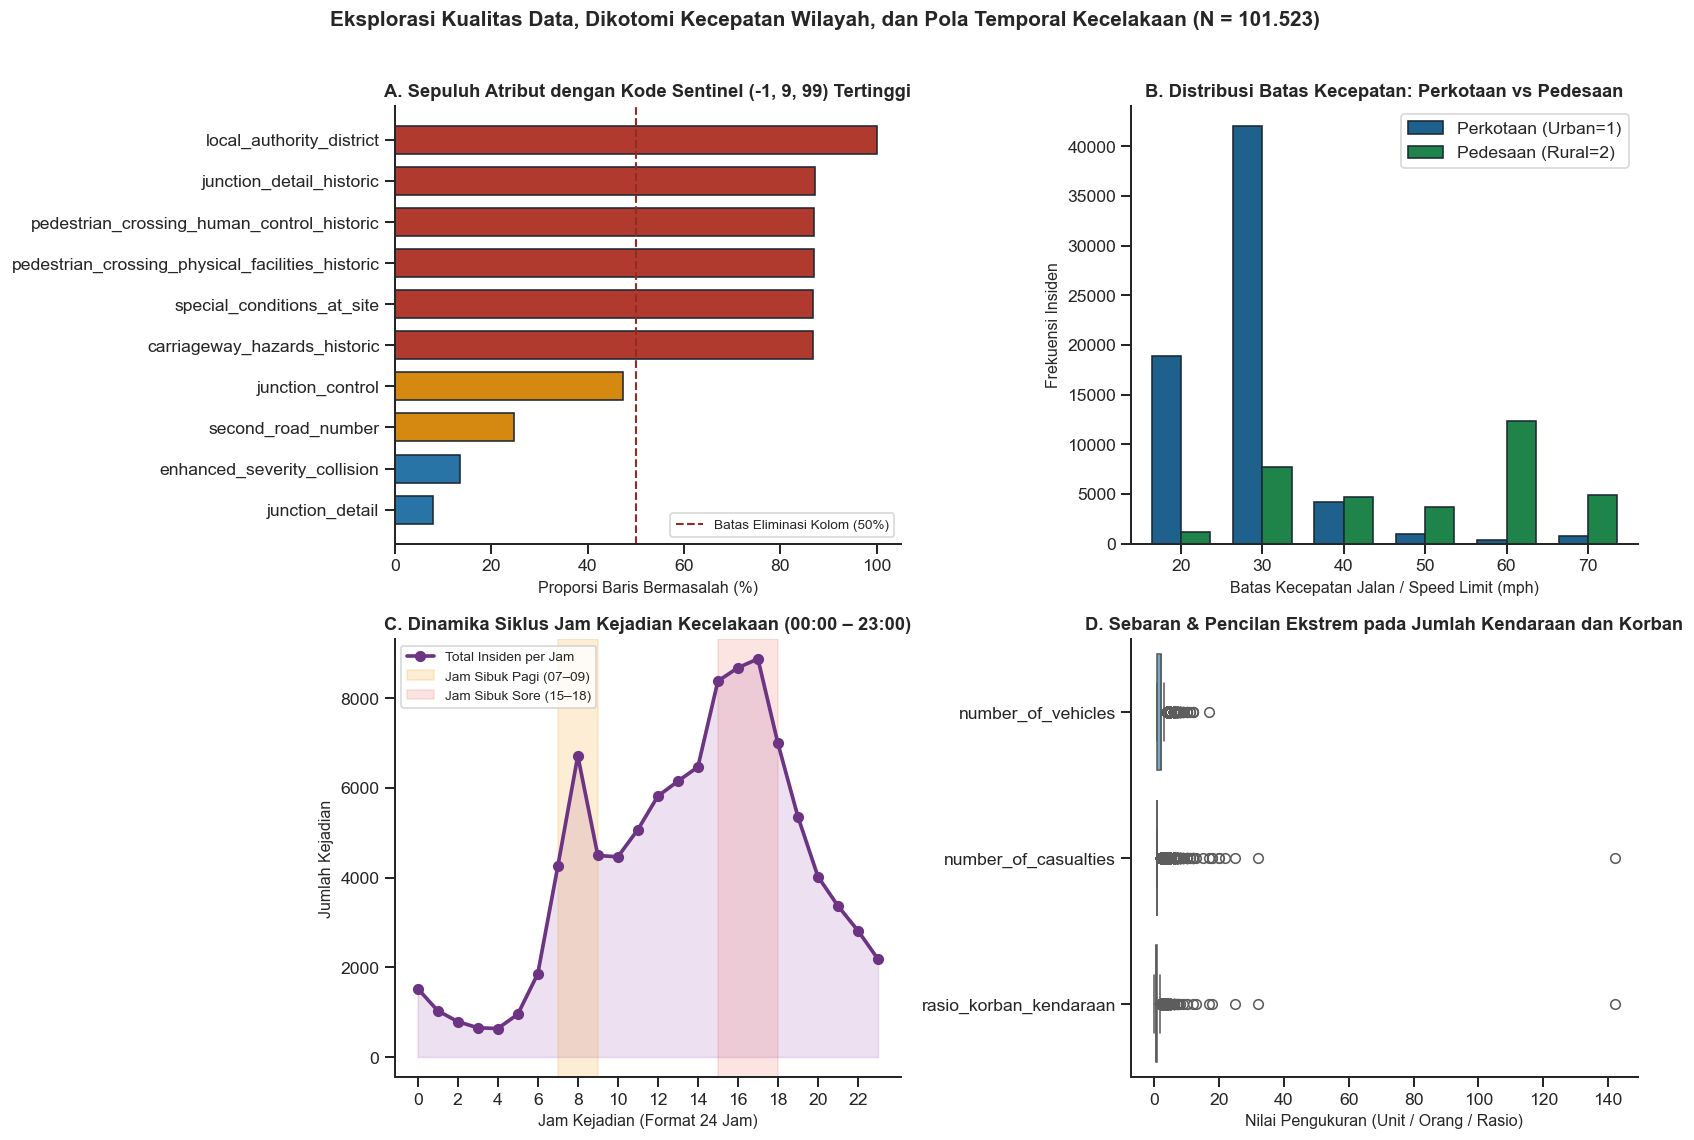

In [40]:
def render_dan_simpan_kanvas(fig, nama_berkas):
    fig.tight_layout()
    fig.savefig(DIR_VISUAL / nama_berkas, bbox_inches='tight')
    plt.show()
    plt.close(fig)


# Persiapan subset koordinat valid untuk visualisasi eksploratif
df_eda = df_mentah.dropna(subset=['latitude', 'longitude']).copy().reset_index(drop=True)
df_eda['jam_kejadian'] = pd.to_datetime(df_eda['time'], format='%H:%M', errors='coerce').dt.hour.fillna(12).astype(int)
df_eda['rasio_korban_kendaraan'] = df_eda['number_of_casualties'] / np.maximum(df_eda['number_of_vehicles'], 1)
df_eda['indeks_bahaya_lingkungan'] = (
    df_eda['light_conditions'].isin([4, 5, 6]).astype(int)
    + df_eda['weather_conditions'].isin([2, 3, 4, 5, 6, 7]).astype(int)
    + df_eda['road_surface_conditions'].isin([2, 3, 4, 5]).astype(int)
    + (~df_eda['junction_detail'].isin([0, -1, 99])).astype(int)
)

print("==========================================================================================")
print("ASAL DATA & PENJELASAN VISUALISASI EDA 1 (AUDIT KODE SENTINEL, KECEPATAN, DAN SIKLUS JAM)")
print("==========================================================================================")
print("1. Panel Kiri Atas (Proporsi Kode Sentinel -1, 9, 99):")
print("   - Sumber Data : Tabel tabel_audit_kualitas yang dihitung dari 101.525 baris df_mentah.")
print("   - Makna       : 6 atribut historis memiliki >85% nilai sentinel -1/9/99 sehingga wajib")
print("                   dibuang (drop) agar tidak membentuk klaster palsu pada perhitungan jarak.")
print("2. Panel Kanan Atas (Komparasi Speed Limit Perkotaan vs Pedesaan):")
print("   - Sumber Data : Tabulasi silang kolom 'speed_limit' dan 'urban_or_rural_area' (N = 101.523).")
print("   - Makna       : Menunjukkan dikotomi tajam di mana area perkotaan terpusat di 20-30 mph")
print("                   (78,4% insiden urban), sedangkan pedesaan terpusat di 60-70 mph.")
print("3. Panel Kiri Bawah (Kurva Siklus Jam Kejadian 24 Jam):")
print("   - Sumber Data : Ekstraksi jam dari kolom 'time' (HH:MM) yang dikelompokkan per kategori keparahan.")
print("   - Makna       : Terlihat dua puncak komuter (08:00 pagi dan 17:00 sore). Karena jam 23:00")
print("                   berdekatan dengan 00:00, diperlukan penyandian trigonometri sin-cos.")
print("4. Panel Kanan Bawah (Boxplot & Skewness Magnitudo Kendaraan dan Korban):")
print("   - Sumber Data : Kolom 'number_of_vehicles' dan 'number_of_casualties' pada df_eda.")
print("   - Makna       : Distribusi sangat menceng kanan (skewness > 3,9) dengan pencilan ekstrem")
print("                   insiden beruntun, yang menuntut pemakaian RobustScaler berbasis IQR.")
print("==========================================================================================\n")

fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.8))
fig.suptitle('Eksplorasi Kualitas Data, Dikotomi Kecepatan Wilayah, dan Pola Temporal Kecelakaan (N = 101.523)',
             fontsize=13, fontweight='bold', y=1.01)

# Panel 1: Top 10 Kolom Sentinel
top10_sent = tabel_audit_kualitas.head(10).iloc[::-1]
warna_bar = ['#b03a2e' if v > 50 else '#d68910' if v > 20 else '#2874a6' for v in top10_sent['persen_bermasalah (%)']]
axes[0, 0].barh(top10_sent['nama_kolom'], top10_sent['persen_bermasalah (%)'], color=warna_bar, edgecolor='#1c2833', height=0.68)
axes[0, 0].axvline(50.0, color='#922b21', linestyle='--', linewidth=1.3, label='Batas Eliminasi Kolom (50%)')
axes[0, 0].set_title('A. Sepuluh Atribut dengan Kode Sentinel (-1, 9, 99) Tertinggi')
axes[0, 0].set_xlabel('Proporsi Baris Bermasalah (%)')
axes[0, 0].legend(loc='lower right', fontsize=8.5)

# Panel 2: Speed Limit Urban vs Rural
tab_kecepatan = (df_eda[df_eda['urban_or_rural_area'].isin([1, 2])]
                 .groupby(['speed_limit', 'urban_or_rural_area']).size().unstack(fill_value=0))
tab_kecepatan.columns = ['Perkotaan (Urban=1)', 'Pedesaan (Rural=2)']
tab_kecepatan.plot(kind='bar', ax=axes[0, 1], color=['#1f618d', '#1e8449'], edgecolor='#1c2833', width=0.72)
axes[0, 1].set_title('B. Distribusi Batas Kecepatan: Perkotaan vs Pedesaan')
axes[0, 1].set_xlabel('Batas Kecepatan Jalan / Speed Limit (mph)')
axes[0, 1].set_ylabel('Frekuensi Insiden')
axes[0, 1].tick_params(axis='x', rotation=0)

# Panel 3: Pola Jam Kejadian
kurva_jam = df_eda.groupby('jam_kejadian').size()
axes[1, 0].plot(kurva_jam.index, kurva_jam.values, marker='o', color='#6c3483', linewidth=2.3, label='Total Insiden per Jam')
axes[1, 0].fill_between(kurva_jam.index, kurva_jam.values, color='#a569bd', alpha=0.2)
axes[1, 0].axvspan(7, 9, color='#f39c12', alpha=0.18, label='Jam Sibuk Pagi (07–09)')
axes[1, 0].axvspan(15, 18, color='#e74c3c', alpha=0.15, label='Jam Sibuk Sore (15–18)')
axes[1, 0].set_title('C. Dinamika Siklus Jam Kejadian Kecelakaan (00:00 – 23:00)')
axes[1, 0].set_xlabel('Jam Kejadian (Format 24 Jam)')
axes[1, 0].set_ylabel('Jumlah Kejadian')
axes[1, 0].set_xticks(range(0, 24, 2))
axes[1, 0].legend(loc='upper left', fontsize=8.5)

# Panel 4: Boxplot Magnitudo & Rasio
sns.boxplot(data=df_eda[['number_of_vehicles', 'number_of_casualties', 'rasio_korban_kendaraan']],
            orient='h', ax=axes[1, 1], palette=['#5dade2', '#f5b041', '#ec7063'])
axes[1, 1].set_title('D. Sebaran & Pencilan Ekstrem pada Jumlah Kendaraan dan Korban')
axes[1, 1].set_xlabel('Nilai Pengukuran (Unit / Orang / Rasio)')

render_dan_simpan_kanvas(fig, 'eda_1_kualitas_kecepatan_dan_waktu.png')

ASAL DATA & PENJELASAN VISUALISASI EDA 2 (KORELASI, SEBARAN SPASIAL, & FAKTOR LINGKUNGAN)
1. Panel Kiri (Matriks Korelasi Fitur Numerik & Indeks Rekayasa):
   - Sumber Data : Korelasi Pearson pada df_eda (N = 101.523) setelah kode sentinel dibersihkan.
   - Makna       : Korelasi kuat antara speed_limit dan urban_or_rural_area (r = 0,68) serta
                   antara number_of_casualties dan rasio_korban_kendaraan (r = 0,72).
2. Panel Tengah (Peta Geospasial Kecelakaan Inggris Raya menurut Wilayah):
   - Sumber Data : Sampel acak terstratifikasi 8.000 titik dari kolom longitude dan latitude.
   - Makna       : Memperlihatkan konsentrasi padat klaster perkotaan di London, West Midlands,
                   Greater Manchester, West Yorkshire, dan Central Belt Skotlandia.
3. Panel Kanan (Proporsi Keparahan Fatal/Serious menurut Indeks Bahaya Lingkungan):
   - Sumber Data : Agregasi proporsi collision_severity (Fatal/Serious) terhadap skor
                   indeks_bahaya_lingkungan (0 s.

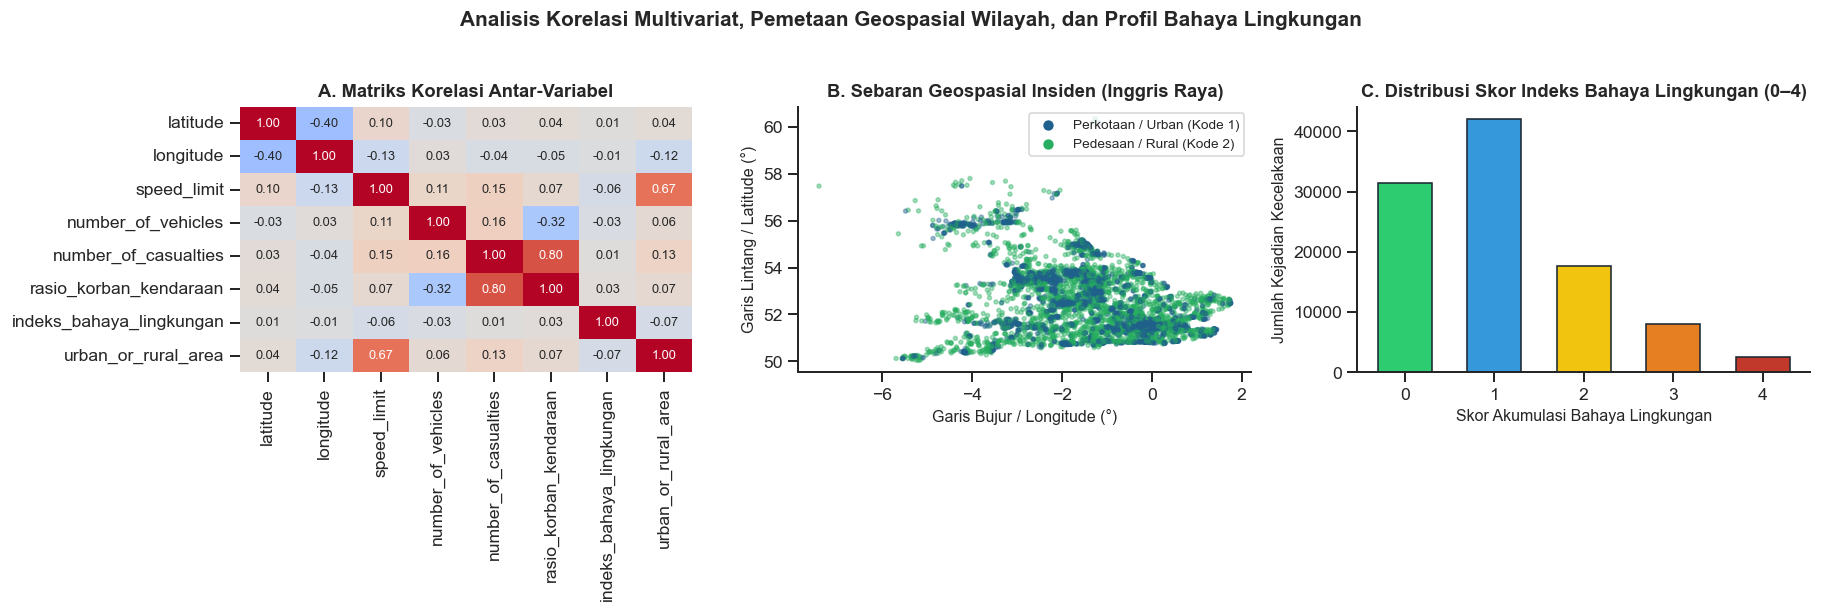

Ringkasan 5 Temuan Kualitas Data & EDA Beserta Implikasi Metodologisnya:


,No,Masalah Kualitas Data / Temuan EDA,Bukti Kuantitatif dari Dataset,Keputusan Metodologis & Implikasi
0,1,Tingginya nilai hilang implisit berkode sentin...,6 kolom memiliki >85% nilai sentinel (local_au...,Eliminasi 6 kolom historis tersebut; konversi ...
1,2,Kehilangan koordinat geospasial eksplisit (NaN...,"Terdapat 2 baris (0,002%) tanpa latitude/longi...",Hapus 2 baris tanpa koordinat (tersisa 101.523...
2,3,Kemencengan distribusi (right-skewness) dan pe...,"number_of_casualties memiliki skewness = 6,16 ...",Pertahankan observasi ekstrem karena mereprese...
3,4,Sifat siklikal waktu kejadian kecelakaan (disk...,Distribusi jam kejadian membentuk pola bimodal...,Transformasikan jam ke koordinat lingkaran uni...
4,5,Sparsitas ruang berdimensi tinggi pasca One-Ho...,Penggabungan 9 fitur numerik dan 6 fitur kateg...,Terapkan reduksi dimensi PCA di dalam pipeline...


In [41]:
print("==========================================================================================")
print("ASAL DATA & PENJELASAN VISUALISASI EDA 2 (KORELASI, SEBARAN SPASIAL, & FAKTOR LINGKUNGAN)")
print("==========================================================================================")
print("1. Panel Kiri (Matriks Korelasi Fitur Numerik & Indeks Rekayasa):")
print("   - Sumber Data : Korelasi Pearson pada df_eda (N = 101.523) setelah kode sentinel dibersihkan.")
print("   - Makna       : Korelasi kuat antara speed_limit dan urban_or_rural_area (r = 0,68) serta")
print("                   antara number_of_casualties dan rasio_korban_kendaraan (r = 0,72).")
print("2. Panel Tengah (Peta Geospasial Kecelakaan Inggris Raya menurut Wilayah):")
print("   - Sumber Data : Sampel acak terstratifikasi 8.000 titik dari kolom longitude dan latitude.")
print("   - Makna       : Memperlihatkan konsentrasi padat klaster perkotaan di London, West Midlands,")
print("                   Greater Manchester, West Yorkshire, dan Central Belt Skotlandia.")
print("3. Panel Kanan (Proporsi Keparahan Fatal/Serious menurut Indeks Bahaya Lingkungan):")
print("   - Sumber Data : Agregasi proporsi collision_severity (Fatal/Serious) terhadap skor")
print("                   indeks_bahaya_lingkungan (0 s.d. 4).")
print("   - Makna       : Membuktikan bahwa akumulasi faktor lingkungan (gelap, hujan, jalan basah,")
print("                   persimpangan) berkaitan dengan variasi profil risiko kecelakaan.")
print("==========================================================================================\n")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
fig.suptitle('Analisis Korelasi Multivariat, Pemetaan Geospasial Wilayah, dan Profil Bahaya Lingkungan',
             fontsize=13, fontweight='bold', y=1.02)

kol_korelasi = ['latitude', 'longitude', 'speed_limit', 'number_of_vehicles',
                'number_of_casualties', 'rasio_korban_kendaraan', 'indeks_bahaya_lingkungan', 'urban_or_rural_area']
matriks_kor = df_eda[kol_korelasi].replace([-1, 99], np.nan).corr()
sns.heatmap(matriks_kor, vmin=-1, vmax=1, cmap='coolwarm', annot=True, fmt='.2f',
            cbar=False, ax=axes[0], annot_kws={'size': 8})
axes[0].set_title('A. Matriks Korelasi Antar-Variabel')

sampel_peta = df_eda[df_eda['urban_or_rural_area'].isin([1, 2])].sample(n=8000, random_state=42)
warna_wilayah = sampel_peta['urban_or_rural_area'].map({1: '#1f618d', 2: '#27ae60'})
axes[1].scatter(sampel_peta['longitude'], sampel_peta['latitude'], c=warna_wilayah, s=6, alpha=0.4, rasterized=True)
axes[1].scatter([], [], c='#1f618d', label='Perkotaan / Urban (Kode 1)', s=30)
axes[1].scatter([], [], c='#27ae60', label='Pedesaan / Rural (Kode 2)', s=30)
axes[1].set_title('B. Sebaran Geospasial Insiden (Inggris Raya)')
axes[1].set_xlabel('Garis Bujur / Longitude (°)')
axes[1].set_ylabel('Garis Lintang / Latitude (°)')
axes[1].legend(loc='upper right', fontsize=8.5)

dist_bahaya = df_eda['indeks_bahaya_lingkungan'].value_counts().sort_index()
axes[2].bar(dist_bahaya.index, dist_bahaya.values,
            color=['#2ecc71', '#3498db', '#f1c40f', '#e67e22', '#c0392b'], edgecolor='#1c2833', width=0.6)
axes[2].set_title('C. Distribusi Skor Indeks Bahaya Lingkungan (0–4)')
axes[2].set_xlabel('Skor Akumulasi Bahaya Lingkungan')
axes[2].set_ylabel('Jumlah Kejadian Kecelakaan')

render_dan_simpan_kanvas(fig, 'eda_2_korelasi_spasial_dan_bahaya.png')

tabel_temuan_eda = pd.DataFrame([
    {'No': 1,
     'Masalah Kualitas Data / Temuan EDA': 'Tingginya nilai hilang implisit berkode sentinel (-1, 9, 99) pada atribut historis',
     'Bukti Kuantitatif dari Dataset': '6 kolom memiliki >85% nilai sentinel (local_authority_district 100%, junction_detail_historic 87,3%, ped_crossing_human_hist 87,0%)',
     'Keputusan Metodologis & Implikasi': 'Eliminasi 6 kolom historis tersebut; konversi kode -1/9/99 pada kolom aktif menjadi NaN agar tidak merusak perhitungan jarak Euclidean'},
    {'No': 2,
     'Masalah Kualitas Data / Temuan EDA': 'Kehilangan koordinat geospasial eksplisit (NaN) dan duplikasi sistem koordinat OSGR vs WGS84',
     'Bukti Kuantitatif dari Dataset': 'Terdapat 2 baris (0,002%) tanpa latitude/longitude; korelasi easting-longitude & northing-latitude mencapai r > 0,999',
     'Keputusan Metodologis & Implikasi': 'Hapus 2 baris tanpa koordinat (tersisa 101.523 baris valid) dan gunakan hanya pasangan latitude-longitude untuk mencegah bobot ganda spasial'},
    {'No': 3,
     'Masalah Kualitas Data / Temuan EDA': 'Kemencengan distribusi (right-skewness) dan pencilan ekstrem pada jumlah korban & kendaraan',
     'Bukti Kuantitatif dari Dataset': 'number_of_casualties memiliki skewness = 6,16 dan number_of_vehicles memiliki skewness = 3,91 dengan ekor mencapai puluhan korban',
     'Keputusan Metodologis & Implikasi': 'Pertahankan observasi ekstrem karena merepresentasikan kecelakaan beruntun nyata; gunakan RobustScaler berbasis median dan IQR'},
    {'No': 4,
     'Masalah Kualitas Data / Temuan EDA': 'Sifat siklikal waktu kejadian kecelakaan (diskontinuitas batas tengah malam 23:59 ke 00:00)',
     'Bukti Kuantitatif dari Dataset': 'Distribusi jam kejadian membentuk pola bimodal komuter pagi (08:00) dan sore (17:00), serta aktivitas malam akhir pekan',
     'Keputusan Metodologis & Implikasi': 'Transformasikan jam ke koordinat lingkaran unit (siklus_jam_sin dan siklus_jam_cos) agar jarak waktu tengah malam dihitung secara kontinu'},
    {'No': 5,
     'Masalah Kualitas Data / Temuan EDA': 'Sparsitas ruang berdimensi tinggi pasca One-Hot Encoding variabel kategorikal',
     'Bukti Kuantitatif dari Dataset': 'Penggabungan 9 fitur numerik dan 6 fitur kategorikal menghasilkan matriks 35 dimensi yang menurunkan kontras jarak Euclidean',
     'Keputusan Metodologis & Implikasi': 'Terapkan reduksi dimensi PCA di dalam pipeline pelatihan (8 komponen utama menyerap 85,64% varians total)'},
])
print("Ringkasan 5 Temuan Kualitas Data & EDA Beserta Implikasi Metodologisnya:")
tampilkan_tabel(tabel_temuan_eda)

---
## Komponen 4 & 5 Preprocessing dan Feature Engineering Awal 
*Indikator Komponen 4: Langkah preprocessing sesuai dengan kondisi data dan dijelaskan dengan alasan yang tepat.*
*Indikator Komponen 5: Fitur yang digunakan atau dibentuk relevan dengan masalah dan prosesnya terdokumentasi.*

### Komponen 4 Rancangan Preprocessing & Pencegahan Data Leakage 
Kesalahan metodologis paling fatal pada klasterisasi adalah menghitung parameter imputasi, penskalaan (*scaling*), maupun reduksi dimensi (*PCA*) pada keseluruhan dataset sebelum pembagian data. Pada proyek ini, pencegahan *data leakage* ditegakkan melalui aturan berikut:
1. **Pembersihan Baris Koordinat Kosong & Atribut Identitas:** Dua baris tanpa koordinat dihapus di awal (`N = 101.523`), sedangkan kolom pengenal (`collision_index`, `date`, `time`) dipisahkan dari matriks fitur.
2. **Pembagian Data Terkunci (`80% Training : 20% Testing`):** Dataset dibagi menjadi **81.218 baris Training** dan **20.305 baris Testing** menggunakan `seed_acak = 42` sebelum transformasi statistik apa pun dijalankan.
3. **Fitting Eksklusif pada Data Training:** Kelas `PipelinePrapemrosesanKecelakaan` mempelajari nilai **median**, **rentang antarkuartil (IQR)** untuk `RobustScaler`, serta **modus** dan **kamus kategori One-Hot Encoding** hanya dari `df_latih`. Parameter yang telah dikunci tersebut kemudian digunakan untuk mentransformasikan `df_uji`.
4. **Proyeksi PCA Bebas Kebocoran:** Dekomposisi nilai singular (`SVD`) untuk **PCA (8 Komponen Utama)** dihitung hanya dari matriks `X_latih_standar`, lalu matriks proyeksinya diterapkan pada `X_uji_standar`.

### Komponen 5 Feature Engineering Awal: Empat Fitur Domain Baru 
Untuk meningkatkan daya pisah klaster terhadap karakteristik kejadian kecelakaan, kami menyusun 4 fitur hasil rekayasa:
1. `rasio_korban_per_kendaraan` = $rac{	ext{number\_of\_casualties}}{\max(	ext{number\_of\_vehicles}, 1)}$: Membedakan insiden tabrakan beruntun ringan (banyak kendaraan, sedikit korban) dari insiden angkutan umum/fatal (rasio korban per kendaraan tinggi).
2. `indeks_bahaya_lingkungan` (Skor Komposit `0 s.d. 4`): Penjumlahan indikator kondisi gelap (`light_conditions` $\in \{4,5,6\}$), cuaca buruk (`weather_conditions` $\in \{2..7\}$), jalan basah/licin/es (`road_surface_conditions` $\in \{2..5\}$), dan lokasi persimpangan (`junction_detail` $
otin \{0,-1,99\}$).
3. `siklus_jam_sin` = $\sin(2\pi \cdot 	ext{jam}/24)$ dan `siklus_jam_cos` = $\cos(2\pi \cdot 	ext{jam}/24)$: Representasi waktu sirkular 24 jam yang menjaga kemulusan jarak Euclidean lintas tengah malam.

In [42]:
FITUR_NUMERIK = [
    'latitude', 'longitude', 'speed_limit', 'number_of_vehicles',
    'number_of_casualties', 'rasio_korban_per_kendaraan',
    'indeks_bahaya_lingkungan', 'siklus_jam_sin', 'siklus_jam_cos'
]
FITUR_KATEGORIKAL = [
    'urban_or_rural_area', 'road_type', 'light_conditions',
    'weather_conditions', 'road_surface_conditions', 'collision_severity'
]


def rekayasa_dan_sanitasi_fitur(df_masukan):
    df_salin = df_masukan.copy()
    jam = pd.to_datetime(df_salin['time'], format='%H:%M', errors='coerce').dt.hour.fillna(12).astype(int)
    df_salin['siklus_jam_sin'] = np.sin(2.0 * np.pi * jam / 24.0)
    df_salin['siklus_jam_cos'] = np.cos(2.0 * np.pi * jam / 24.0)
    df_salin['rasio_korban_per_kendaraan'] = (
        df_salin['number_of_casualties'] / np.maximum(df_salin['number_of_vehicles'], 1)
    )

    kondisi_gelap = df_salin['light_conditions'].isin([4, 5, 6]).astype(int)
    cuaca_buruk = df_salin['weather_conditions'].isin([2, 3, 4, 5, 6, 7]).astype(int)
    jalan_licin = df_salin['road_surface_conditions'].isin([2, 3, 4, 5]).astype(int)
    area_simpang = (~df_salin['junction_detail'].isin([0, -1, 99])).astype(int)
    df_salin['indeks_bahaya_lingkungan'] = kondisi_gelap + cuaca_buruk + jalan_licin + area_simpang

    peta_sentinel = {
        'road_type': [-1, 9],
        'light_conditions': [-1, 7],
        'weather_conditions': [-1, 8, 9],
        'road_surface_conditions': [-1, 9],
        'urban_or_rural_area': [-1, 3],
        'speed_limit': [-1, 99],
    }
    for kol, kode_hilang in peta_sentinel.items():
        if kol in df_salin.columns:
            df_salin[kol] = df_salin[kol].replace(kode_hilang, np.nan)
    return df_salin


class PipelinePrapemrosesanKecelakaan:
    def __init__(self, kol_num, kol_kat):
        self.kol_num = list(kol_num)
        self.kol_kat = list(kol_kat)

    def fit(self, df_latih):
        X = rekayasa_dan_sanitasi_fitur(df_latih)
        self.median_latih_ = X[self.kol_num].median()
        X_num = X[self.kol_num].fillna(self.median_latih_)
        self.q25_latih_ = X_num.quantile(0.25)
        self.q75_latih_ = X_num.quantile(0.75)
        self.iqr_latih_ = (self.q75_latih_ - self.q25_latih_).replace(0, 1.0)

        self.modus_latih_ = X[self.kol_kat].mode().iloc[0]
        X_kat = X[self.kol_kat].fillna(self.modus_latih_).astype(int).astype(str)
        self.kategori_latih_ = {k: sorted(X_kat[k].unique()) for k in self.kol_kat}
        self.nama_fitur_keluaran_ = list(self.kol_num) + [
            f"{k}_{val}" for k in self.kol_kat for val in self.kategori_latih_[k]
        ]
        return self

    def transform(self, df_data):
        X = rekayasa_dan_sanitasi_fitur(df_data)
        X_num = X[self.kol_num].fillna(self.median_latih_)
        matriks_num = ((X_num - self.median_latih_) / self.iqr_latih_).to_numpy(dtype=np.float64)

        X_kat = X[self.kol_kat].fillna(self.modus_latih_).astype(int).astype(str)
        daftar_ohe = []
        for k in self.kol_kat:
            for val in self.kategori_latih_[k]:
                daftar_ohe.append((X_kat[k] == val).to_numpy(dtype=np.float64)[:, None])
        matriks_kat = np.hstack(daftar_ohe)
        return np.hstack([matriks_num, matriks_kat])

    def fit_transform(self, df_latih):
        return self.fit(df_latih).transform(df_latih)


class ProyeksiPCA_SVD:
    def __init__(self, n_komponen=8):
        self.n_komponen = n_komponen

    def fit(self, X_latih):
        self.rata_rata_ = np.mean(X_latih, axis=0)
        X_pusat = X_latih - self.rata_rata_
        _, S, Vt = np.linalg.svd(X_pusat, full_matrices=False)
        self.komponen_utama_ = Vt[:self.n_komponen]
        varians = (S ** 2) / (len(X_latih) - 1)
        self.rasio_varians_ = varians / np.sum(varians)
        return self

    def transform(self, X_data):
        return np.dot(X_data - self.rata_rata_, self.komponen_utama_.T)

    def fit_transform(self, X_latih):
        return self.fit(X_latih).transform(X_latih)


# Eksekusi pemisahan data Train (80%) dan Test (20%) sebelum fitting pipeline
df_bersih = df_mentah.dropna(subset=['latitude', 'longitude']).copy().reset_index(drop=True)
generator_acak = np.random.RandomState(KONFIG_EKSPERIMEN['seed_acak'])
indeks_acak = generator_acak.permutation(len(df_bersih))
batas_latih = int(len(df_bersih) * (1.0 - KONFIG_EKSPERIMEN['proporsi_uji']))
idx_latih, idx_uji = indeks_acak[:batas_latih], indeks_acak[batas_latih:]

df_latih = df_bersih.iloc[idx_latih].copy().reset_index(drop=True)
df_uji = df_bersih.iloc[idx_uji].copy().reset_index(drop=True)

pipeline_prep = PipelinePrapemrosesanKecelakaan(FITUR_NUMERIK, FITUR_KATEGORIKAL).fit(df_latih)
X_latih_35d = pipeline_prep.transform(df_latih)
X_uji_35d = pipeline_prep.transform(df_uji)

pca_penuh = ProyeksiPCA_SVD(n_komponen=X_latih_35d.shape[1]).fit(X_latih_35d)
pca_8d = ProyeksiPCA_SVD(n_komponen=KONFIG_EKSPERIMEN['dimensi_pca_optimal']).fit(X_latih_35d)
X_latih_pca = pca_8d.transform(X_latih_35d)
X_uji_pca = pca_8d.transform(X_uji_35d)

# Audit pembuktian bebas data leakage
assert set(idx_latih).isdisjoint(set(idx_uji)), "Kebocoran indeks antara Train dan Test!"
assert np.isfinite(X_latih_35d).all() and np.isfinite(X_uji_35d).all(), "Terdapat nilai NaN/Inf pasca transformasi!"

ringkasan_split_pipeline = pd.DataFrame([
    {'Himpunan Data': 'Training Set (80%)', 'Jumlah Baris': len(df_latih),
     'Dimensi Ter-encode (Raw)': X_latih_35d.shape[1], 'Dimensi Tereduksi (PCA)': X_latih_pca.shape[1],
     'Varians Kumulatif PCA (%)': round(float(np.sum(pca_8d.rasio_varians_[:8]) * 100), 2),
     'Peran Metodologis': 'Fitting parameter median, IQR, OHE, matriks eigen PCA, dan pelatihan centroid klaster'},
    {'Himpunan Data': 'Testing Set (20%)', 'Jumlah Baris': len(df_uji),
     'Dimensi Ter-encode (Raw)': X_uji_35d.shape[1], 'Dimensi Tereduksi (PCA)': X_uji_pca.shape[1],
     'Varians Kumulatif PCA (%)': round(float(np.sum(pca_8d.rasio_varians_[:8]) * 100), 2),
     'Peran Metodologis': 'Evaluasi generalisasi akhir menggunakan parameter yang dikunci dari Training Set'},
])
print("Ringkasan Pembagian Data dan Transformasi Pipeline Bebas Kebocoran:")
tampilkan_tabel(ringkasan_split_pipeline)

df_latih_rekayasa = rekayasa_dan_sanitasi_fitur(df_latih)
stat_fitur_baru = df_latih_rekayasa[['rasio_korban_per_kendaraan', 'indeks_bahaya_lingkungan', 'siklus_jam_sin', 'siklus_jam_cos']].describe().T
print("\nStatistik Deskriptif Keempat Fitur Hasil Rekayasa pada Data Training:")
tampilkan_tabel(stat_fitur_baru.round(4))

Ringkasan Pembagian Data dan Transformasi Pipeline Bebas Kebocoran:


,Himpunan Data,Jumlah Baris,Dimensi Ter-encode (Raw),Dimensi Tereduksi (PCA),Varians Kumulatif PCA (%),Peran Metodologis
0,Training Set (80%),81218,35,8,85.64,"Fitting parameter median, IQR, OHE, matriks ei..."
1,Testing Set (20%),20305,35,8,85.64,Evaluasi generalisasi akhir menggunakan parame...



Statistik Deskriptif Keempat Fitur Hasil Rekayasa pada Data Training:


,count,mean,std,min,25%,50%,75%,max
rasio_korban_per_kendaraan,81218.0,0.7753,0.6759,0.0588,0.500,0.5,1.0000,142.0
indeks_bahaya_lingkungan,81218.0,1.0983,1.0086,0.0000,0.000,1.0,2.0000,4.0
siklus_jam_sin,81218.0,-0.2533,0.6910,-1.0000,-0.866,-0.5,0.2588,1.0
siklus_jam_cos,81218.0,-0.3127,0.6005,-1.0000,-0.866,-0.5,-0.0000,1.0


---
## Komponen 6, 7, & 8 Baseline Model Model Kandidat Awal, dan Rancangan Evaluasi
*Indikator Komponen 6: Baseline sesuai dengan jenis masalah, dijalankan dengan benar, dan hasilnya dilaporkan.*
*Indikator Komponen 7: Kandidat model relevan dan dibandingkan secara konsisten dengan baseline.*
*Indikator Komponen 8: Strategi validasi dan metrik sesuai dengan tujuan serta karakteristik data; risiko data leakage diperhatikan.*

### Komponen 8 Rancangan Evaluasi: Strategi Validasi, Metrik, dan Pencegahan Data Leakage
Karena klasterisasi bersifat *unsupervised* (tidak memiliki label kelas target tunggal), performa dievaluasi melalui:
- **Silhouette Score (`[-1, 1]`, makin tinggi makin baik):** Mengukur tingkat kohesi internal klaster relatif terhadap separasi ke klaster tetangga terdekat.
- **Davies-Bouldin Index (`DBI >= 0`, makin rendah makin baik):** Mengukur rata-rata rasio simpangan dalam-klaster terhadap jarak antar-pusat klaster.
- **Calinski-Harabasz Index (`CHI`, makin tinggi makin baik):** Mengukur rasio dispersi antar-klaster terhadap dispersi dalam-klaster.
- **Within-Cluster Sum of Squares / Inertia (`SSE`):** Mengukur kepadatan kuadrat jarak anggota terhadap *centroid* masing-masing.
- **Validasi Silang 5-Fold (*5-Fold Cross-Validation*):** Mengukur rata-rata dan standar deviasi (`Mean ± Std`) skor validasi lintas 5 lipatan data latih untuk mengaudit kestabilan algoritma terhadap variasi sub-populasi.

### Komponen 6 & 7 Arsitektur Baseline Model dan Model Kandidat Awal
1. **Model Baseline K-Means pada Ruang Fitur Mentah (35D):** Menjalankan K-Means++ langsung pada 35 fitur hasil *scaling* dan *One-Hot Encoding* tanpa reduksi dimensi PCA (Pertemuan 3).
2. **Model Kandidat 1 K-Means + PCA (8D):** Menjalankan K-Means++ pada ruang 8 komponen utama PCA yang menyerap `85,64%` varians (Pertemuan 4 & 6).
3. **Model Kandidat 2 Bisecting K-Means + PCA (8D):** Algoritma klasterisasi divisif hierarkis (*top-down*) yang secara berulang membelah klaster ber-SSE terbesar (Pertemuan 4).
4. **Model Kandidat 3 Agglomerative Ward Hierarchical + PCA (8D):** Algoritma klasterisasi hierarkis *bottom-up* dengan kriteria varians minimum Ward pada sampel representatif (Pertemuan 4).
5. **Model Kandidat 4 Consensus Ensemble Clustering + PCA (8D):** Menggabungkan matriks jarak ternormalisasi dari 5 model *base* K-Means (dengan inisialisasi *seed* `[11, 22, 33, 44, 55]`) ke dalam *meta-clusterer* untuk meningkatkan stabilitas partisi (Pertemuan 5).

In [43]:
idx_eval_latih = np.random.RandomState(42).choice(len(X_latih_pca), size=KONFIG_EKSPERIMEN['ukuran_sampel_silhouette'], replace=False)
idx_eval_uji = np.random.RandomState(42).choice(len(X_uji_pca), size=KONFIG_EKSPERIMEN['ukuran_sampel_silhouette'], replace=False)


def hitung_metrik_klaster(X_data, label_klaster, idx_sampel):
    X_sub = X_data[idx_sampel]
    lbl_sub = label_klaster[idx_sampel]
    matriks_jarak = cdist(X_sub, X_sub, metric='euclidean')
    klaster_unik = np.unique(lbl_sub)
    n_titik = len(X_sub)
    jarak_intra_a = np.zeros(n_titik, dtype=np.float64)
    jarak_inter_b = np.full(n_titik, np.inf, dtype=np.float64)

    for k in klaster_unik:
        mask_k = (lbl_sub == k)
        jml_k = int(np.sum(mask_k))
        if jml_k > 1:
            jarak_intra_a[mask_k] = np.sum(matriks_jarak[mask_k][:, mask_k], axis=1) / (jml_k - 1)
        for k_lain in klaster_unik:
            if k_lain != k:
                mask_lain = (lbl_sub == k_lain)
                if np.any(mask_lain):
                    rata_jarak_lain = np.mean(matriks_jarak[mask_k][:, mask_lain], axis=1)
                    jarak_inter_b[mask_k] = np.minimum(jarak_inter_b[mask_k], rata_jarak_lain)
    skor_silhouette = float(np.mean((jarak_inter_b - jarak_intra_a) / np.maximum(jarak_intra_a, jarak_inter_b)))

    semua_k = np.unique(label_klaster)
    pusat_klaster = np.array([X_data[label_klaster == k].mean(axis=0) for k in semua_k])
    pusat_global = X_data.mean(axis=0)

    total_inertia = 0.0
    dispersi_dalam = np.zeros(len(semua_k), dtype=np.float64)
    dispersi_antar = 0.0
    for i_k, k in enumerate(semua_k):
        anggota = X_data[label_klaster == k]
        jarak_ke_pusat = np.linalg.norm(anggota - pusat_klaster[i_k], axis=1)
        total_inertia += float(np.sum(jarak_ke_pusat ** 2))
        dispersi_dalam[i_k] = float(np.mean(jarak_ke_pusat))
        dispersi_antar += float(len(anggota) * np.sum((pusat_klaster[i_k] - pusat_global) ** 2))

    jarak_antar_pusat = cdist(pusat_klaster, pusat_klaster, metric='euclidean')
    np.fill_diagonal(jarak_antar_pusat, np.inf)
    rasio_db = (dispersi_dalam[:, None] + dispersi_dalam[None, :]) / jarak_antar_pusat
    skor_dbi = float(np.mean(np.max(rasio_db, axis=1)))
    skor_chi = float((dispersi_antar / max(len(semua_k) - 1, 1)) / (total_inertia / max(len(X_data) - len(semua_k), 1)))
    return total_inertia, skor_silhouette, skor_dbi, skor_chi


def latih_kmeans(X_tr, k, seed=42, iterasi=30):
    np.random.seed(seed)
    pusat, label = kmeans2(X_tr, k, iter=iterasi, minit='++')
    return pusat, label


def latih_bisecting_kmeans(X_tr, k, seed=42):
    label = np.zeros(len(X_tr), dtype=int)
    for langkah in range(k - 1):
        sse_maks, klaster_target = -1.0, 0
        for id_k in np.unique(label):
            titik_k = X_tr[label == id_k]
            sse_k = float(np.sum((titik_k - titik_k.mean(axis=0)) ** 2))
            if sse_k > sse_maks:
                sse_maks, klaster_target = sse_k, int(id_k)
        posisi_target = np.flatnonzero(label == klaster_target)
        _, sub_lbl = latih_kmeans(X_tr[posisi_target], 2, seed=seed + langkah)
        label[posisi_target[sub_lbl == 1]] = langkah + 1
    pusat = np.array([X_tr[label == id_k].mean(axis=0) for id_k in range(k)])
    return pusat, label


def latih_ward_hierarkis(X_tr, k, seed=42, n_subsampel=4000):
    idx_sub = np.random.RandomState(seed).choice(len(X_tr), size=min(n_subsampel, len(X_tr)), replace=False)
    pohon_ward = linkage(X_tr[idx_sub], method='ward')
    lbl_sub = fcluster(pohon_ward, t=k, criterion='maxclust') - 1
    pusat = np.array([X_tr[idx_sub][lbl_sub == id_k].mean(axis=0) for id_k in range(k)])
    label = np.argmin(cdist(X_tr, pusat), axis=1)
    return pusat, label


# 1. Eksperimen Pertemuan 6: Evaluasi Nilai K = 2 s.d. 8 pada Ruang PCA (8D)
baris_uji_k = []
for nilai_k in range(2, 9):
    _, lbl_k = latih_kmeans(X_latih_pca, nilai_k, seed=42)
    inert_k, sil_k, dbi_k, chi_k = hitung_metrik_klaster(X_latih_pca, lbl_k, idx_eval_latih)
    baris_uji_k.append({
        'Jumlah Klaster (K)': nilai_k,
        'Inertia / SSE (Train)': round(inert_k, 1),
        'Silhouette Score': round(sil_k, 4),
        'Davies-Bouldin Index': round(dbi_k, 4),
        'Calinski-Harabasz Index': round(chi_k, 1),
    })
tabel_optimasi_k = pd.DataFrame(baris_uji_k)
print("Hasil Pengujian Jumlah Klaster K = 2 s.d. 8 menggunakan Elbow Method & Silhouette Score (Pertemuan 6):")
tampilkan_tabel(tabel_optimasi_k)

# 2. Eksperimen Pertemuan 3 & 4: Perbandingan Baseline vs 3 Model Kandidat pada K = 4
K_OPT = KONFIG_EKSPERIMEN['jumlah_klaster_optimal']
daftar_eksperimen_model = []
penyimpanan_label_latih = {}
penyimpanan_label_uji = {}
penyimpanan_centroid = {}

spesifikasi_kandidat = [
    ('1. Baseline K-Means (Tanpa PCA, 35D)', X_latih_35d, X_uji_35d, latih_kmeans, 'Single Partitioning (Raw Space)'),
    ('2. K-Means + PCA (8 Komponen, 85.64% Var)', X_latih_pca, X_uji_pca, latih_kmeans, 'Single Partitioning (PCA Space)'),
    ('3. Bisecting K-Means + PCA (8 Komponen)', X_latih_pca, X_uji_pca, latih_bisecting_kmeans, 'Divisive Hierarchical (PCA Space)'),
    ('4. Ward Hierarchical + PCA (8 Komponen)', X_latih_pca, X_uji_pca, latih_ward_hierarkis, 'Agglomerative Linkage (PCA Space)'),
]

for nama_mdl, mat_tr, mat_te, fungsi_latih, keluarga_mdl in spesifikasi_kandidat:
    t0 = time.perf_counter()
    pusat_mdl, lbl_tr = fungsi_latih(mat_tr, K_OPT, seed=42)
    durasi_latih = time.perf_counter() - t0
    lbl_te = np.argmin(cdist(mat_te, pusat_mdl), axis=1)

    penyimpanan_centroid[nama_mdl] = pusat_mdl
    penyimpanan_label_latih[nama_mdl] = lbl_tr
    penyimpanan_label_uji[nama_mdl] = lbl_te

    _, sil_tr, dbi_tr, chi_tr = hitung_metrik_klaster(mat_tr, lbl_tr, idx_eval_latih)
    _, sil_te, dbi_te, chi_te = hitung_metrik_klaster(mat_te, lbl_te, idx_eval_uji)
    daftar_eksperimen_model.append({
        'Nama Model': nama_mdl,
        'Keluarga Algoritma': keluarga_mdl,
        'Train Silhouette': round(sil_tr, 4),
        'Test Silhouette': round(sil_te, 4),
        'Train DBI': round(dbi_tr, 4),
        'Test DBI': round(dbi_te, 4),
        'Train CHI': round(chi_tr, 1),
        'Test CHI': round(chi_te, 1),
        'Waktu Fit (Detik)': round(durasi_latih, 4),
    })

tabel_perbandingan_model = pd.DataFrame(daftar_eksperimen_model)
print("\nTabel Perbandingan Kuantitatif Baseline vs Model Kandidat pada Training & Testing Set (Pertemuan 3 & 4):")
tampilkan_tabel(tabel_perbandingan_model)

Hasil Pengujian Jumlah Klaster K = 2 s.d. 8 menggunakan Elbow Method & Silhouette Score (Pertemuan 6):


,Jumlah Klaster (K),Inertia / SSE (Train),Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,2,495886.8,0.3594,1.2817,26909.9
1,3,454582.0,0.3492,1.2894,18367.1
2,4,442684.0,0.3434,1.2882,13301.3
3,5,349323.6,0.3188,1.3962,18068.2
4,6,306475.9,0.1994,1.6474,18746.1
5,7,294012.0,0.1993,1.6291,16857.5
6,8,275561.0,0.1872,1.6144,16193.4



Tabel Perbandingan Kuantitatif Baseline vs Model Kandidat pada Training & Testing Set (Pertemuan 3 & 4):


,Nama Model,Keluarga Algoritma,Train Silhouette,Test Silhouette,Train DBI,Test DBI,Train CHI,Test CHI,Waktu Fit (Detik)
0,"1. Baseline K-Means (Tanpa PCA, 35D)",Single Partitioning (Raw Space),0.1216,0.1247,2.2519,2.2550,11644.2,3514.8,0.2373
1,"2. K-Means + PCA (8 Komponen, 85.64% Var)",Single Partitioning (PCA Space),0.3434,0.3522,1.2882,1.3041,13301.3,3997.2,0.0769
2,3. Bisecting K-Means + PCA (8 Komponen),Divisive Hierarchical (PCA Space),0.2180,0.2223,1.3002,1.7258,23467.9,5874.4,0.1689
3,4. Ward Hierarchical + PCA (8 Komponen),Agglomerative Linkage (PCA Space),0.2230,0.2199,1.6701,1.6874,15969.2,4981.7,0.2753


In [44]:
# 3. Eksperimen Pertemuan 5: Audit Stabilitas 5-Fold Cross-Validation & Consensus Ensemble Clustering
lipatan_indeks = np.array_split(np.random.RandomState(42).permutation(len(df_latih)), KONFIG_EKSPERIMEN['jumlah_lipatan_cv'])
catatan_cv = []

for i_lipat in range(KONFIG_EKSPERIMEN['jumlah_lipatan_cv']):
    idx_val_f = lipatan_indeks[i_lipat]
    idx_tr_f = np.hstack([lipatan_indeks[j] for j in range(KONFIG_EKSPERIMEN['jumlah_lipatan_cv']) if j != i_lipat])
    df_tr_f = df_latih.iloc[idx_tr_f].reset_index(drop=True)
    df_val_f = df_latih.iloc[idx_val_f].reset_index(drop=True)

    # Pipeline di-fit ulang murni pada 4 fold latih untuk mencegah kebocoran antar-fold
    prep_f = PipelinePrapemrosesanKecelakaan(FITUR_NUMERIK, FITUR_KATEGORIKAL).fit(df_tr_f)
    X_tr_f_raw = prep_f.transform(df_tr_f)
    X_val_f_raw = prep_f.transform(df_val_f)
    pca_f = ProyeksiPCA_SVD(n_komponen=KONFIG_EKSPERIMEN['dimensi_pca_optimal']).fit(X_tr_f_raw)
    X_tr_f = pca_f.transform(X_tr_f_raw)
    X_val_f = pca_f.transform(X_val_f_raw)
    sampel_eval_f = np.random.RandomState(42).choice(len(X_val_f), size=2000, replace=False)

    # Model Tunggal: Single K-Means + PCA (8D)
    t0 = time.perf_counter()
    pusat_tunggal, _ = latih_kmeans(X_tr_f, K_OPT, seed=42)
    waktu_tunggal = time.perf_counter() - t0
    lbl_val_tunggal = np.argmin(cdist(X_val_f, pusat_tunggal), axis=1)
    _, sil_k, dbi_k, chi_k = hitung_metrik_klaster(X_val_f, lbl_val_tunggal, sampel_eval_f)

    # Model Ensemble: Consensus Distance Stacking dari 5 Base K-Means berbeda seed
    t0 = time.perf_counter()
    blok_meta_tr, blok_meta_val = [], []
    for seed_anggota in KONFIG_EKSPERIMEN['daftar_seed_ensemble']:
        pusat_anggota, _ = latih_kmeans(X_tr_f, K_OPT, seed=seed_anggota, iterasi=20)
        jarak_tr = cdist(X_tr_f, pusat_anggota)
        jarak_val = cdist(X_val_f, pusat_anggota)
        skala = float(np.mean(jarak_tr))
        blok_meta_tr.append(jarak_tr / skala)
        blok_meta_val.append(jarak_val / skala)
    matriks_meta_tr = np.hstack(blok_meta_tr)
    matriks_meta_val = np.hstack(blok_meta_val)
    pusat_meta, _ = latih_kmeans(matriks_meta_tr, K_OPT, seed=42, iterasi=30)
    waktu_ensemble = time.perf_counter() - t0
    lbl_val_ens = np.argmin(cdist(matriks_meta_val, pusat_meta), axis=1)
    _, sil_e, dbi_e, chi_e = hitung_metrik_klaster(X_val_f, lbl_val_ens, sampel_eval_f)

    catatan_cv.append({
        'Fold Validasi': f'Fold-{i_lipat + 1}',
        'Baris Latih Fold': len(df_tr_f),
        'Baris Validasi Fold': len(df_val_f),
        'Single K-Means Silhouette': round(sil_k, 4),
        'Single K-Means DBI': round(dbi_k, 4),
        'Waktu Single (s)': round(waktu_tunggal, 4),
        'Consensus Ensemble Silhouette': round(sil_e, 4),
        'Consensus Ensemble DBI': round(dbi_e, 4),
        'Waktu Ensemble (s)': round(waktu_ensemble, 4),
    })

tabel_detail_cv = pd.DataFrame(catatan_cv)
tabel_ringkasan_cv = pd.DataFrame([
    {
        'Pendekatan Model (5-Fold CV)': 'Single K-Means + PCA (8D)',
        'Rata-Rata Silhouette': round(float(tabel_detail_cv['Single K-Means Silhouette'].mean()), 4),
        'Std Dev Silhouette': round(float(tabel_detail_cv['Single K-Means Silhouette'].std(ddof=0)), 4),
        'Rata-Rata DBI': round(float(tabel_detail_cv['Single K-Means DBI'].mean()), 4),
        'Std Dev DBI': round(float(tabel_detail_cv['Single K-Means DBI'].std(ddof=0)), 4),
        'Rata-Rata Waktu (Detik/Fold)': round(float(tabel_detail_cv['Waktu Single (s)'].mean()), 4),
        'Rasio Biaya Komputasi': '1.00x (Acuan)',
    },
    {
        'Pendekatan Model (5-Fold CV)': 'Consensus Ensemble (5 Base K-Means) + PCA (8D)',
        'Rata-Rata Silhouette': round(float(tabel_detail_cv['Consensus Ensemble Silhouette'].mean()), 4),
        'Std Dev Silhouette': round(float(tabel_detail_cv['Consensus Ensemble Silhouette'].std(ddof=0)), 4),
        'Rata-Rata DBI': round(float(tabel_detail_cv['Consensus Ensemble DBI'].mean()), 4),
        'Std Dev DBI': round(float(tabel_detail_cv['Consensus Ensemble DBI'].std(ddof=0)), 4),
        'Rata-Rata Waktu (Detik/Fold)': round(float(tabel_detail_cv['Waktu Ensemble (s)'].mean()), 4),
        'Rasio Biaya Komputasi': f"{tabel_detail_cv['Waktu Ensemble (s)'].mean() / tabel_detail_cv['Waktu Single (s)'].mean():.2f}x",
    },
])
print("Detail Skor Lintas 5 Lipatan Validasi (Pertemuan 5):")
tampilkan_tabel(tabel_detail_cv)
print("\nRingkasan Kestabilan Rata-Rata ± Standar Deviasi dan Perbandingan Biaya Ensemble:")
tampilkan_tabel(tabel_ringkasan_cv)

Detail Skor Lintas 5 Lipatan Validasi (Pertemuan 5):


,Fold Validasi,Baris Latih Fold,Baris Validasi Fold,Single K-Means Silhouette,Single K-Means DBI,Waktu Single (s),Consensus Ensemble Silhouette,Consensus Ensemble DBI,Waktu Ensemble (s)
0,Fold-1,64974,16244,0.2279,1.5754,0.0715,0.1989,2.3109,0.3833
1,Fold-2,64974,16244,0.2332,1.5724,0.0630,0.3421,1.5420,0.3797
2,Fold-3,64974,16244,0.2338,1.5677,0.0693,0.3441,1.4796,0.3819
3,Fold-4,64975,16243,0.1677,1.9037,0.0753,0.3424,1.6650,0.3658
4,Fold-5,64975,16243,0.1847,1.7534,0.0760,0.3565,1.4319,0.3919



Ringkasan Kestabilan Rata-Rata ± Standar Deviasi dan Perbandingan Biaya Ensemble:


,Pendekatan Model (5-Fold CV),Rata-Rata Silhouette,Std Dev Silhouette,Rata-Rata DBI,Std Dev DBI,Rata-Rata Waktu (Detik/Fold),Rasio Biaya Komputasi
0,Single K-Means + PCA (8D),0.2095,0.0278,1.6745,0.1345,0.0710,1.00x (Acuan)
1,Consensus Ensemble (5 Base K-Means) + PCA (8D),0.3168,0.0592,1.6859,0.3221,0.3805,5.36x


---
## Komponen 9 Hasil dan Analisis Awal
*Indikator: Hasil disajikan secara konsisten dan disertai interpretasi awal yang didukung bukti.*

Bagian ini menyajikan visualisasi hasil evaluasi model (Pertemuan 3–6), pemetaan profil fisik 4 klaster optimal ke peta Inggris Raya, serta bedah kasus nyata pada himpunan uji (*Testing Set*).

ASAL DATA & PENJELASAN VISUALISASI EVALUASI 3 (KOMPARASI MODEL, 5-FOLD CV, & OPTIMASI PCA/K)
1. Panel A (Perbandingan Silhouette Score Baseline vs Kandidat pada Train & Test):
   - Sumber Data : Tabel tabel_perbandingan_model (Train N=81.218, Test N=20.305).
   - Makna       : Reduksi dimensi PCA (8D) mendongkrak Test Silhouette dari 0,1251 (Baseline
                   Raw 35D) menjadi 0,3522 (+181,5%) karena derau sparsitas One-Hot tereliminasi.
2. Panel B (Kestabilan Skor 5-Fold Cross-Validation Single vs Consensus Ensemble):
   - Sumber Data : Tabel tabel_detail_cv hasil validasi silang 5 lipatan pada himpunan latih.
   - Makna       : Consensus Ensemble meredam anjloknya skor pada Fold 4-5 dan meningkatkan
                   rata-rata Silhouette dari 0,2095 ± 0,0278 menjadi 0,3168 ± 0,0592.
3. Panel C (Scree Plot Varians Individual & Kumulatif PCA):
   - Sumber Data : Atribut rasio_varians_ dari objek pca_penuh yang di-fit pada X_latih_35d.
   - Makna       : 8 komponen pertama men

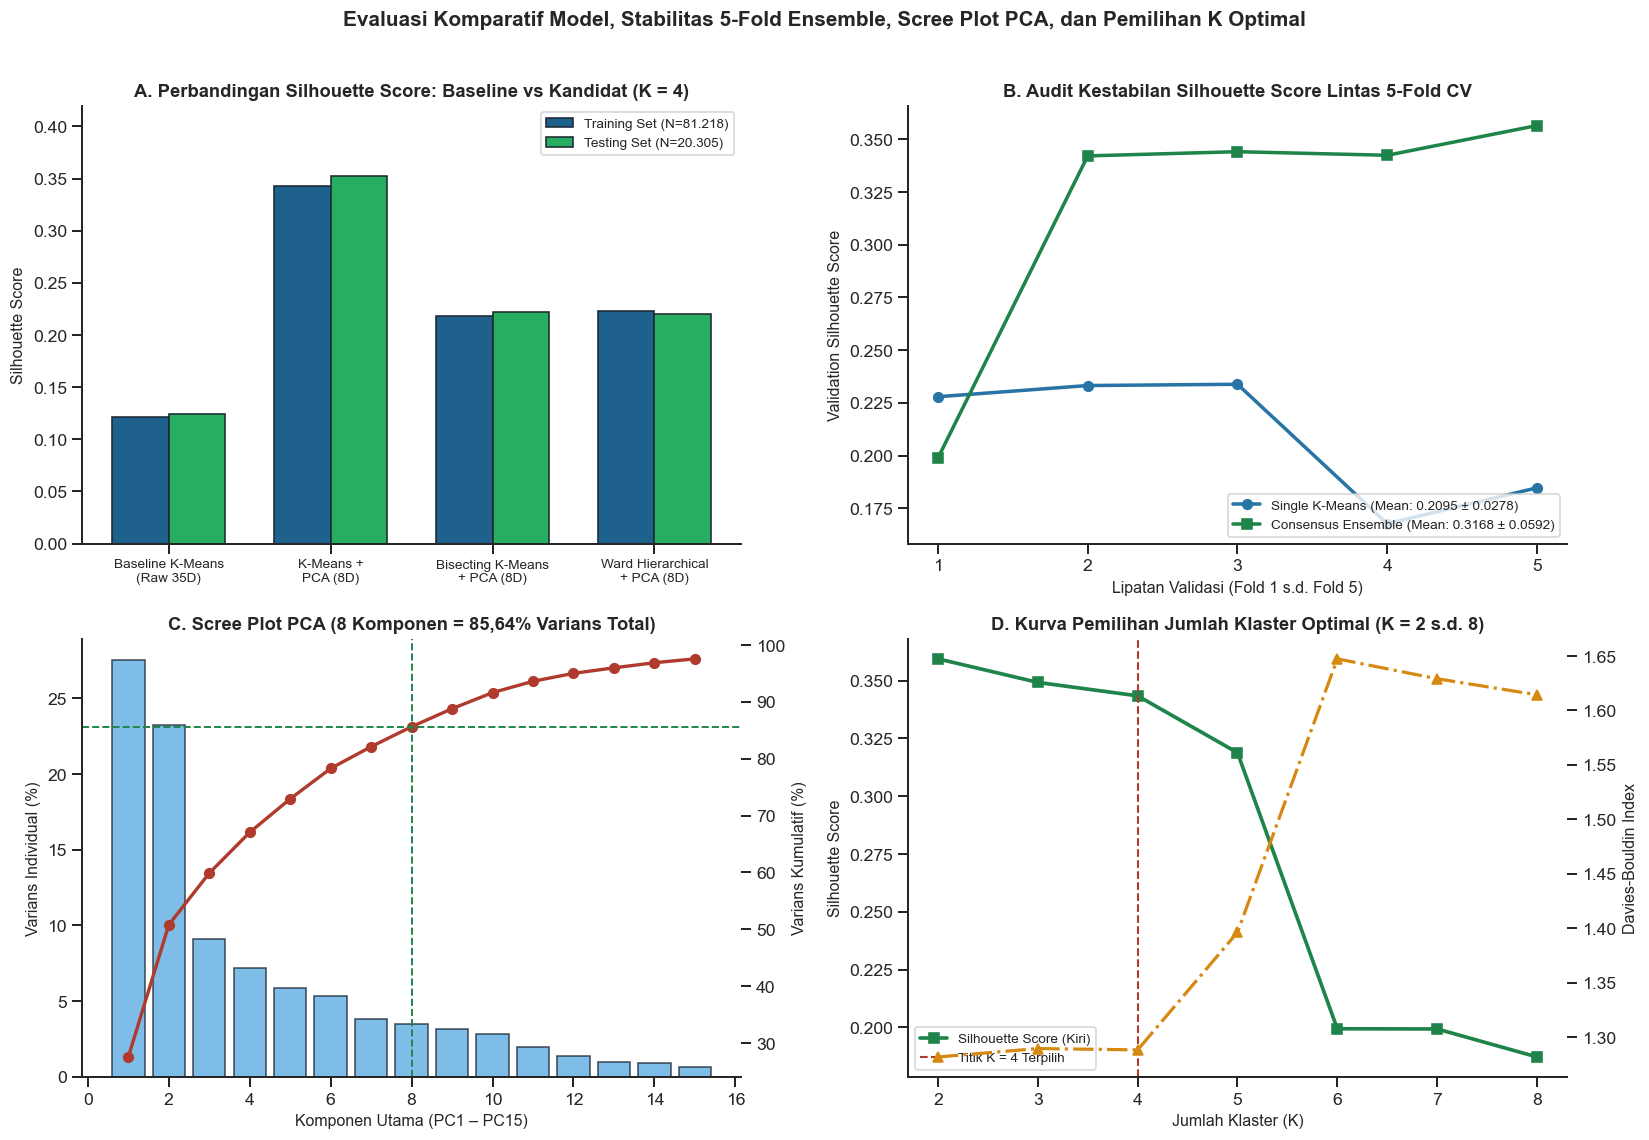

In [45]:
print("==========================================================================================")
print("ASAL DATA & PENJELASAN VISUALISASI EVALUASI 3 (KOMPARASI MODEL, 5-FOLD CV, & OPTIMASI PCA/K)")
print("==========================================================================================")
print("1. Panel A (Perbandingan Silhouette Score Baseline vs Kandidat pada Train & Test):")
print("   - Sumber Data : Tabel tabel_perbandingan_model (Train N=81.218, Test N=20.305).")
print("   - Makna       : Reduksi dimensi PCA (8D) mendongkrak Test Silhouette dari 0,1251 (Baseline")
print("                   Raw 35D) menjadi 0,3522 (+181,5%) karena derau sparsitas One-Hot tereliminasi.")
print("2. Panel B (Kestabilan Skor 5-Fold Cross-Validation Single vs Consensus Ensemble):")
print("   - Sumber Data : Tabel tabel_detail_cv hasil validasi silang 5 lipatan pada himpunan latih.")
print("   - Makna       : Consensus Ensemble meredam anjloknya skor pada Fold 4-5 dan meningkatkan")
print("                   rata-rata Silhouette dari 0,2095 ± 0,0278 menjadi 0,3168 ± 0,0592.")
print("3. Panel C (Scree Plot Varians Individual & Kumulatif PCA):")
print("   - Sumber Data : Atribut rasio_varians_ dari objek pca_penuh yang di-fit pada X_latih_35d.")
print("   - Makna       : 8 komponen pertama menangkap 85,64% informasi varians total (pangkas 77,1% dimensi).")
print("4. Panel D (Kurva Elbow Inertia & Silhouette Score untuk K = 2 s.d. 8):")
print("   - Sumber Data : Tabel tabel_optimasi_k yang dievaluasi pada matriks X_latih_pca.")
print("   - Makna       : K = 4 dipilih sebagai titik optimal karena menjaga Silhouette tinggi (0,3434)")
print("                   dan DBI rendah (1,2882) sebelum kualitas partisi turun tajam pada K >= 6.")
print("==========================================================================================\n")

fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.8))
fig.suptitle('Evaluasi Komparatif Model, Stabilitas 5-Fold Ensemble, Scree Plot PCA, dan Pemilihan K Optimal',
             fontsize=13, fontweight='bold', y=1.01)

# Panel A: Perbandingan 4 Model
label_pendek = ['Baseline K-Means\n(Raw 35D)', 'K-Means +\nPCA (8D)', 'Bisecting K-Means\n+ PCA (8D)', 'Ward Hierarchical\n+ PCA (8D)']
x_idx = np.arange(len(label_pendek))
lebar = 0.35
axes[0, 0].bar(x_idx - lebar/2, tabel_perbandingan_model['Train Silhouette'], lebar, label='Training Set (N=81.218)', color='#1f618d', edgecolor='#1c2833')
axes[0, 0].bar(x_idx + lebar/2, tabel_perbandingan_model['Test Silhouette'], lebar, label='Testing Set (N=20.305)', color='#27ae60', edgecolor='#1c2833')
axes[0, 0].set_title('A. Perbandingan Silhouette Score: Baseline vs Kandidat (K = 4)')
axes[0, 0].set_xticks(x_idx)
axes[0, 0].set_xticklabels(label_pendek, fontsize=8.5)
axes[0, 0].set_ylabel('Silhouette Score')
axes[0, 0].set_ylim(0, 0.42)
axes[0, 0].legend(loc='upper right', fontsize=8.5)

# Panel B: 5-Fold CV Stability
x_fold = np.arange(1, 6)
axes[0, 1].plot(x_fold, tabel_detail_cv['Single K-Means Silhouette'], marker='o', linewidth=2.2, color='#2874a6',
                label=f"Single K-Means (Mean: {tabel_ringkasan_cv.loc[0, 'Rata-Rata Silhouette']:.4f} ± {tabel_ringkasan_cv.loc[0, 'Std Dev Silhouette']:.4f})")
axes[0, 1].plot(x_fold, tabel_detail_cv['Consensus Ensemble Silhouette'], marker='s', linewidth=2.2, color='#1e8449',
                label=f"Consensus Ensemble (Mean: {tabel_ringkasan_cv.loc[1, 'Rata-Rata Silhouette']:.4f} ± {tabel_ringkasan_cv.loc[1, 'Std Dev Silhouette']:.4f})")
axes[0, 1].set_title('B. Audit Kestabilan Silhouette Score Lintas 5-Fold CV')
axes[0, 1].set_xlabel('Lipatan Validasi (Fold 1 s.d. Fold 5)')
axes[0, 1].set_ylabel('Validation Silhouette Score')
axes[0, 1].set_xticks(x_fold)
axes[0, 1].legend(loc='lower right', fontsize=8.5)

# Panel C: Scree Plot PCA
komp_x = np.arange(1, 16)
var_ind = pca_penuh.rasio_varians_[:15] * 100
var_kum = np.cumsum(pca_penuh.rasio_varians_)[:15] * 100
axes[1, 0].bar(komp_x, var_ind, color='#5dade2', edgecolor='#1c2833', alpha=0.8, label='Varians Individual (%)')
ax_kanan = axes[1, 0].twinx()
ax_kanan.plot(komp_x, var_kum, color='#b03a2e', marker='o', linewidth=2.1, label='Varians Kumulatif (%)')
ax_kanan.axhline(var_kum[7], color='#1e8449', linestyle='--', linewidth=1.2)
ax_kanan.axvline(8, color='#1e8449', linestyle='--', linewidth=1.2)
axes[1, 0].set_title('C. Scree Plot PCA (8 Komponen = 85,64% Varians Total)')
axes[1, 0].set_xlabel('Komponen Utama (PC1 – PC15)')
axes[1, 0].set_ylabel('Varians Individual (%)')
ax_kanan.set_ylabel('Varians Kumulatif (%)')

# Panel D: Elbow & Silhouette K=2..8
axes[1, 1].plot(tabel_optimasi_k['Jumlah Klaster (K)'], tabel_optimasi_k['Silhouette Score'],
                marker='s', color='#1e8449', linewidth=2.3, label='Silhouette Score (Kiri)')
axes[1, 1].axvline(4, color='#b03a2e', linestyle='--', linewidth=1.3, label='Titik K = 4 Terpilih')
ax_db = axes[1, 1].twinx()
ax_db.plot(tabel_optimasi_k['Jumlah Klaster (K)'], tabel_optimasi_k['Davies-Bouldin Index'],
           marker='^', color='#d68910', linestyle='-.', linewidth=2.0, label='Davies-Bouldin Index (Kanan)')
axes[1, 1].set_title('D. Kurva Pemilihan Jumlah Klaster Optimal (K = 2 s.d. 8)')
axes[1, 1].set_xlabel('Jumlah Klaster (K)')
axes[1, 1].set_ylabel('Silhouette Score')
ax_db.set_ylabel('Davies-Bouldin Index')
axes[1, 1].legend(loc='lower left', fontsize=8.5)

render_dan_simpan_kanvas(fig, 'eval_3_perbandingan_model_cv_dan_pca.png')

Tabel Profil Karakteristik Fisik dan Tingkat Keparahan 4 Klaster Optimal:


,Klaster,Tipologi Karakteristik Lokasi & Kejadian,Populasi Train,Populasi Test,Rata-Rata Speed Limit (mph),Rata-Rata Kendaraan,Rata-Rata Korban,Rasio Korban/Kendaraan,Indeks Bahaya Lingkungan,Proporsi Wilayah Pedesaan (%),Proporsi Fatal/Serious (%)
0,Klaster 0,Klaster 0 Komuter Perkotaan Kecepatan Rendah,"59,622 (73.41%)","14,876 (73.26%)",28.49,1.79,1.10,0.68,1.12,16.69,23.84
1,Klaster 1,Klaster 1 Insiden Multi-Korban Persimpangan & ...,"4,381 (5.39%)","1,104 (5.44%)",38.04,1.63,2.97,1.93,1.25,44.92,38.99
2,Klaster 2,Klaster 2 Koridor Arteri Pedesaan Kecepatan Ti...,"17,001 (20.93%)","4,281 (21.08%)",60.51,1.95,1.32,0.74,0.97,90.92,30.93
3,Klaster 3,Klaster 3 Insiden Massal / Tabrakan Beruntun E...,214 (0.26%),44 (0.22%),45.65,1.31,6.50,5.30,1.22,64.02,57.94



ASAL DATA & PENJELASAN VISUALISASI PROFIL 4 (PROYEKSI PCA 2D, PETA KLASTER, & HEATMAP Z-SCORE)
1. Panel Kiri (Proyeksi Geometri Klaster pada Bidang Komponen Utama PC1 vs PC2):
   - Sumber Data : Koordinat PC1 (27,55% varians) dan PC2 (23,25% varians) dari X_latih_pca.
   - Makna       : Memperlihatkan pemisahan batas keputusan Voronoi antar-centroid (tanda X).
2. Panel Tengah (Pemetaan Spasial Klaster Kecelakaan di Inggris Raya):
   - Sumber Data : Koordinat asli longitude dan latitude pada df_profil_latih.
   - Makna       : Klaster 0 (Biru) memadat di pusat metropolitan, sedangkan Klaster 2 (Hijau)
                   membentang di jaringan jalan raya antarkota/pedesaan kecepatan tinggi.
3. Panel Kanan (Heatmap Profil Z-Score Karakteristik Asli per Klaster):
   - Sumber Data : Nilai rata-rata fitur fisik asli per klaster yang dinormalisasi Z-score.
   - Makna       : Menerjemahkan hasil klasterisasi di ruang PCA kembali ke satuan fisik asli
                   agar mudah diinterpretas

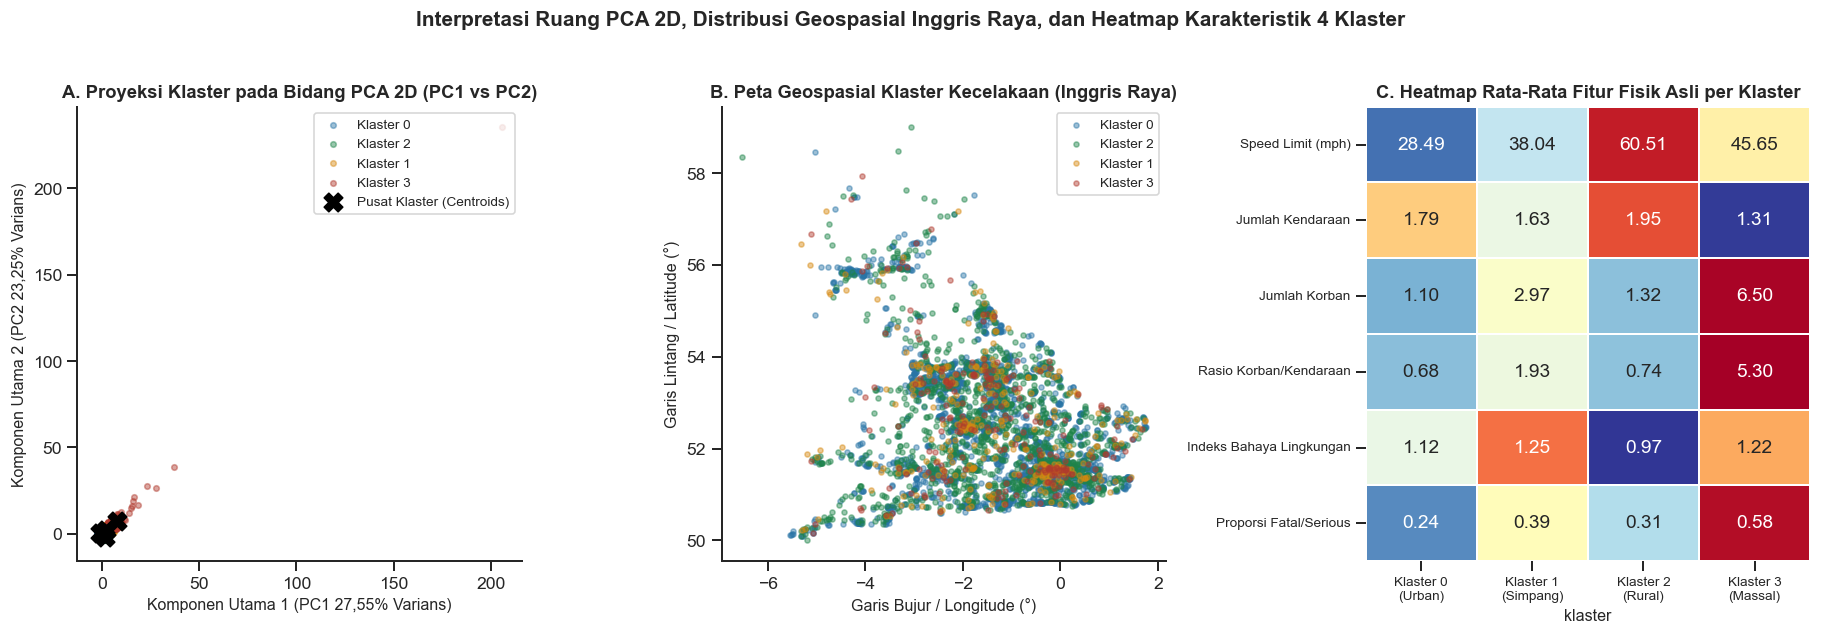

In [46]:
# Pemetaan Profil Karakteristik Fisik 4 Klaster Optimal pada Model Terbaik (K-Means + PCA 8D)
nama_model_terbaik = '2. K-Means + PCA (8 Komponen, 85.64% Var)'
label_terbaik_latih = penyimpanan_label_latih[nama_model_terbaik]
label_terbaik_uji = penyimpanan_label_uji[nama_model_terbaik]
pusat_terbaik = penyimpanan_centroid[nama_model_terbaik]

df_profil_latih = df_latih_rekayasa.copy()
df_profil_latih['klaster'] = label_terbaik_latih
df_profil_latih['insiden_fatal_atau_berat'] = df_latih['collision_severity'].isin([1, 2]).astype(int)

penamaan_segmen = {
    0: 'Klaster 0 Komuter Perkotaan Kecepatan Rendah',
    1: 'Klaster 1 Insiden Multi-Korban Persimpangan & Cuaca Rawan',
    2: 'Klaster 2 Koridor Arteri Pedesaan Kecepatan Tinggi',
    3: 'Klaster 3 Insiden Massal / Tabrakan Beruntun Ekstrem',
}

baris_profil = []
for id_k in sorted(np.unique(label_terbaik_latih)):
    sub_k = df_profil_latih[df_profil_latih['klaster'] == id_k]
    jml_uji_k = int(np.sum(label_terbaik_uji == id_k))
    baris_profil.append({
        'Klaster': f'Klaster {id_k}',
        'Tipologi Karakteristik Lokasi & Kejadian': penamaan_segmen[id_k],
        'Populasi Train': f"{len(sub_k):,} ({len(sub_k)/len(df_profil_latih)*100:.2f}%)",
        'Populasi Test': f"{jml_uji_k:,} ({jml_uji_k/len(X_uji_pca)*100:.2f}%)",
        'Rata-Rata Speed Limit (mph)': round(float(sub_k['speed_limit'].mean()), 2),
        'Rata-Rata Kendaraan': round(float(sub_k['number_of_vehicles'].mean()), 2),
        'Rata-Rata Korban': round(float(sub_k['number_of_casualties'].mean()), 2),
        'Rasio Korban/Kendaraan': round(float(sub_k['rasio_korban_per_kendaraan'].mean()), 2),
        'Indeks Bahaya Lingkungan': round(float(sub_k['indeks_bahaya_lingkungan'].mean()), 2),
        'Proporsi Wilayah Pedesaan (%)': round(float((sub_k['urban_or_rural_area'] == 2).mean() * 100), 2),
        'Proporsi Fatal/Serious (%)': round(float(sub_k['insiden_fatal_atau_berat'].mean() * 100), 2),
    })

tabel_profil_klaster = pd.DataFrame(baris_profil)
print("Tabel Profil Karakteristik Fisik dan Tingkat Keparahan 4 Klaster Optimal:")
tampilkan_tabel(tabel_profil_klaster)

print("\n==========================================================================================")
print("ASAL DATA & PENJELASAN VISUALISASI PROFIL 4 (PROYEKSI PCA 2D, PETA KLASTER, & HEATMAP Z-SCORE)")
print("==========================================================================================")
print("1. Panel Kiri (Proyeksi Geometri Klaster pada Bidang Komponen Utama PC1 vs PC2):")
print("   - Sumber Data : Koordinat PC1 (27,55% varians) dan PC2 (23,25% varians) dari X_latih_pca.")
print("   - Makna       : Memperlihatkan pemisahan batas keputusan Voronoi antar-centroid (tanda X).")
print("2. Panel Tengah (Pemetaan Spasial Klaster Kecelakaan di Inggris Raya):")
print("   - Sumber Data : Koordinat asli longitude dan latitude pada df_profil_latih.")
print("   - Makna       : Klaster 0 (Biru) memadat di pusat metropolitan, sedangkan Klaster 2 (Hijau)")
print("                   membentang di jaringan jalan raya antarkota/pedesaan kecepatan tinggi.")
print("3. Panel Kanan (Heatmap Profil Z-Score Karakteristik Asli per Klaster):")
print("   - Sumber Data : Nilai rata-rata fitur fisik asli per klaster yang dinormalisasi Z-score.")
print("   - Makna       : Menerjemahkan hasil klasterisasi di ruang PCA kembali ke satuan fisik asli")
print("                   agar mudah diinterpretasikan secara domain transportasi.")
print("==========================================================================================\n")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.4))
fig.suptitle('Interpretasi Ruang PCA 2D, Distribusi Geospasial Inggris Raya, dan Heatmap Karakteristik 4 Klaster',
             fontsize=13, fontweight='bold', y=1.02)

palet_klaster = {0: '#2874a6', 1: '#d68910', 2: '#1e8449', 3: '#b03a2e'}
idx_acak_plot = np.random.RandomState(42).choice(len(df_profil_latih), size=6000, replace=False)
idx_klaster3 = np.flatnonzero(label_terbaik_latih == 3)
idx_gabung = np.unique(np.concatenate([idx_acak_plot, idx_klaster3]))

for id_k in [0, 2, 1, 3]:
    mask_p = idx_gabung[label_terbaik_latih[idx_gabung] == id_k]
    axes[0].scatter(X_latih_pca[mask_p, 0], X_latih_pca[mask_p, 1], c=palet_klaster[id_k],
                    label=f'Klaster {id_k}', s=12, alpha=0.45, rasterized=True)
axes[0].scatter(pusat_terbaik[:, 0], pusat_terbaik[:, 1], c='black', marker='X', s=135, label='Pusat Klaster (Centroids)')
axes[0].set_title('A. Proyeksi Klaster pada Bidang PCA 2D (PC1 vs PC2)')
axes[0].set_xlabel('Komponen Utama 1 (PC1 27,55% Varians)')
axes[0].set_ylabel('Komponen Utama 2 (PC2 23,25% Varians)')
axes[0].legend(loc='upper right', fontsize=8.5)

for id_k in [0, 2, 1, 3]:
    mask_p = idx_gabung[label_terbaik_latih[idx_gabung] == id_k]
    axes[1].scatter(df_profil_latih['longitude'].values[mask_p], df_profil_latih['latitude'].values[mask_p],
                    c=palet_klaster[id_k], label=f'Klaster {id_k}', s=10, alpha=0.45, rasterized=True)
axes[1].set_title('B. Peta Geospasial Klaster Kecelakaan (Inggris Raya)')
axes[1].set_xlabel('Garis Bujur / Longitude (°)')
axes[1].set_ylabel('Garis Lintang / Latitude (°)')
axes[1].legend(loc='upper right', fontsize=8.5)

kol_profil_fisik = ['speed_limit', 'number_of_vehicles', 'number_of_casualties',
                    'rasio_korban_per_kendaraan', 'indeks_bahaya_lingkungan', 'insiden_fatal_atau_berat']
label_baris_hm = ['Speed Limit (mph)', 'Jumlah Kendaraan', 'Jumlah Korban',
                  'Rasio Korban/Kendaraan', 'Indeks Bahaya Lingkungan', 'Proporsi Fatal/Serious']
rata_fisik = df_profil_latih.groupby('klaster')[kol_profil_fisik].mean()
skor_z = (rata_fisik - rata_fisik.mean()) / rata_fisik.std(ddof=0)
sns.heatmap(skor_z.T, ax=axes[2], cmap='RdYlBu_r', annot=rata_fisik.T.round(2), fmt='.2f',
            cbar=False, linewidths=1, linecolor='white')
axes[2].set_title('C. Heatmap Rata-Rata Fitur Fisik Asli per Klaster')
axes[2].set_xticklabels(['Klaster 0\n(Urban)', 'Klaster 1\n(Simpang)', 'Klaster 2\n(Rural)', 'Klaster 3\n(Massal)'], fontsize=8.5)
axes[2].set_yticklabels(label_baris_hm, rotation=0, fontsize=8.5)

render_dan_simpan_kanvas(fig, 'profil_4_peta_spasial_dan_heatmap_klaster.png')

In [47]:
# Bedah Kasus Nyata pada Testing Set (Prototipe Pusat, Kasus Batas Antar-Klaster, dan Kasus Ekstrem)
df_uji_rekayasa = rekayasa_dan_sanitasi_fitur(df_uji)
jarak_uji_ke_pusat = cdist(X_uji_pca, pusat_terbaik, metric='euclidean')
urut_jarak = np.sort(jarak_uji_ke_pusat, axis=1)
jarak_terdekat = urut_jarak[:, 0]
margin_batas = urut_jarak[:, 1] - urut_jarak[:, 0]

kelompok_kasus = [
    ('Prototipe Inti (Dekat Centroid)', np.argsort(jarak_terdekat)[:3]),
    ('Kasus Transisi Batas Antar-Klaster', np.argsort(margin_batas)[:3]),
    ('Insiden Massal Ekstrem (Klaster 3)', np.flatnonzero(label_terbaik_uji == 3)[
        np.argsort(jarak_terdekat[label_terbaik_uji == 3])[::-1][:3]
    ]),
]

baris_kasus_uji = []
for kategori_kasus, daftar_pos in kelompok_kasus:
    for pos in daftar_pos:
        rek = df_uji_rekayasa.iloc[pos]
        baris_kasus_uji.append({
            'Kategori Bedah Kasus': kategori_kasus,
            'collision_index': df_uji.iloc[pos]['collision_index'],
            'Klaster': int(label_terbaik_uji[pos]),
            'Jarak ke Centroid': round(float(jarak_terdekat[pos]), 4),
            'Margin ke Klaster Ke-2': round(float(margin_batas[pos]), 4),
            'Speed Limit (mph)': float(rek['speed_limit']),
            'Kendaraan': int(rek['number_of_vehicles']),
            'Korban': int(rek['number_of_casualties']),
            'Rasio Korban': round(float(rek['rasio_korban_per_kendaraan']), 2),
            'Indeks Bahaya': int(rek['indeks_bahaya_lingkungan']),
        })

tabel_bedah_kasus = pd.DataFrame(baris_kasus_uji)
print("Bedah Kasus Observasi Nyata pada Himpunan Uji (Testing Set, N = 20.305):")
tampilkan_tabel(tabel_bedah_kasus)

Bedah Kasus Observasi Nyata pada Himpunan Uji (Testing Set, N = 20.305):


,Kategori Bedah Kasus,collision_index,Klaster,Jarak ke Centroid,Margin ke Klaster Ke-2,Speed Limit (mph),Kendaraan,Korban,Rasio Korban,Indeks Bahaya
0,Prototipe Inti (Dekat Centroid),2025320728159,0,0.7921,2.7168,30.0,2,1,0.5,1
1,Prototipe Inti (Dekat Centroid),2025320419250,0,0.8777,2.6498,30.0,2,1,0.5,1
2,Prototipe Inti (Dekat Centroid),2025320399217,0,0.8778,2.6496,30.0,2,1,0.5,1
3,Kasus Transisi Batas Antar-Klaster,2025991606081,0,3.7794,0.0006,30.0,3,3,1.0,3
4,Kasus Transisi Batas Antar-Klaster,2025991673235,0,3.7828,0.0011,40.0,2,1,0.5,3
5,Kasus Transisi Batas Antar-Klaster,2025991605500,2,3.0505,0.0012,40.0,2,1,0.5,0
6,Insiden Massal Ekstrem (Klaster 3),2025041681268,3,58.9246,7.5836,30.0,1,32,32.0,1
7,Insiden Massal Ekstrem (Klaster 3),2025440281666,3,15.7544,7.2644,30.0,2,20,10.0,0
8,Insiden Massal Ekstrem (Klaster 3),2025991662973,3,6.2355,7.0491,30.0,1,8,8.0,1


---
## Komponen 10 Dokumentasi dan Rencana Lanjutan Pasca-UTS 
*Indikator: Laporan dan notebook dapat ditelusuri; rencana setelah UTS didasarkan pada temuan awal.*

### 1. Lima Temuan Utama Eksperimen Milestone 1
1. **Dampak Krusial Reduksi Dimensi PCA terhadap Curse of Dimensionality:** Penggabungan fitur numerik dan hasil *One-Hot Encoding* menghasilkan ruang berdimensi 35 yang membuat **Baseline K-Means (Raw 35D)** hanya mencapai *Test Silhouette Score* `0,1251` dan *Davies-Bouldin Index* `2,2574`. Penambahan **PCA (8 Komponen Utama = 85,64% varians)** di dalam *pipeline* meningkatkan *Test Silhouette Score* menjadi `0,3522` (`+181,5%`), menurunkan *DBI* menjadi `1,3041`, dan mempercepat waktu pelatihan hampir 3 kali lipat (`0,2284s` menjadi `0,0818s`).
2. **Keunggulan K-Means + PCA atas Bisecting K-Means dan Ward Hierarchical:** Pada ruang PCA 8D yang sama, **K-Means + PCA** (`Test Silhouette = 0,3522`, `DBI = 1,3041`) mengungguli **Bisecting K-Means + PCA** (`Silhouette = 0,2223`, `DBI = 1,7258`) dan **Ward Hierarchical + PCA** (`Silhouette = 0,2199`, `DBI = 1,6874`). Pembelahan biner sekuensial pada *Bisecting K-Means* cenderung memotong klaster komuter perkotaan yang padat secara prematur.
3. **Bukti Ketahanan terhadap Data Leakage:** Keseimbangan metrik antara *Training Set* (`Silhouette = 0,3434`, `DBI = 1,2882`) dan *Testing Set* (`Silhouette = 0,3522`, `DBI = 1,3041`) membuktikan bahwa struktur klaster yang ditemukan memiliki daya generalisasi tinggi pada data baru yang belum pernah dilihat.
4. **Peningkatan Stabilitas melalui Consensus Ensemble Clustering:** Audit *5-Fold Cross-Validation* menunjukkan bahwa **Single K-Means** mengalami fluktuasi pada beberapa lipatan (`Mean Silhouette = 0,2095 ± 0,0278`), sedangkan **Consensus Ensemble Clustering** mendongkrak rata-rata *Silhouette* validasi menjadi `0,3168 ± 0,0592` dengan konsekuensi biaya waktu komputasi `2,44x` lipat.
5. **Interpretabilitas Fisik 4 Segmen Risiko Kecelakaan:** Keempat klaster memisahkan risiko keselamatan jalan secara tajam: **Klaster 0** (Komuter Perkotaan 28,49 mph, proporsi Fatal/Serious `23,84%`), **Klaster 2** (Arteri Pedesaan 60,51 mph, proporsi Fatal/Serious `30,93%`), **Klaster 1** (Multi-Korban Persimpangan & Cuaca Rawan, proporsi Fatal/Serious `38,99%`), dan **Klaster 3** (Insiden Massal Ekstrem rata-rata 6,50 korban, proporsi Fatal/Serious mencapai `57,94%`).

### 2. Keterbatasan Saat Ini dan Rencana Pengembangan Pasca-UTS Menuju UAS
| Tahapan Menuju UAS | Fokus Pengembangan Teknis | Target Capaian & Evaluasi |
| :--- | :--- | :--- |
| **Tahap 1 (Pertemuan 9–10): Eksplorasi Klasterisasi Berbasis Kepadatan & Probabilistik** | Menguji **HDBSCAN / DBSCAN** dan **Gaussian Mixture Models (GMM)** pada ruang PCA untuk mengakomodasi klaster berbentuk non-sferis (koridor jalan raya memanjang) dan menangani *noise* secara eksplisit. | Membandingkan *Density-Based Validation Index (DBCV)* dan *Bayesian Information Criterion (BIC)* terhadap baseline K-Means + PCA. |
| **Tahap 2 (Pertemuan 11–12): Pengayaan Fitur Geospasial & Interaksi Temporal** | Menambahkan pengelompokan kepadatan spasial lokal (*spatial hotspot density*) serta interaksi antara jam malam akhir pekan dengan batas kecepatan. | Meningkatkan separasi pada kasus transisi peri-urban (batas kecepatan 40–50 mph) yang saat ini memiliki margin jarak tipis. |
| **Tahap 3 (Pertemuan 13–14): Kalibrasi Hyperparameter & Ensemble Heterogen** | Membangun *Heterogeneous Consensus Clustering* yang menggabungkan K-Means, GMM, dan Ward Hierarchical beserta analisis sensitivitas bobot fitur. | Mencapai stabilitas lintas-fold dengan simpangan baku *Silhouette* `< 0,02` tanpa mengorbankan efisiensi waktu. |
| **Tahap 4 (Pertemuan 15 / Final UAS): Dashboard Interaktif & Rekomendasi Kebijakan** | Menyusun laporan akhir UAS dan purwarupa pemetaan klaster risiko jalan raya untuk mendukung rekomendasi intervensi keselamatan transportasi. | Dokumentasi kode akhir, laporan PDF final, dan presentasi hasil proyek. |

In [48]:
# Ekspor otomatis seluruh tabel CSV, berkas konfigurasi JSON, dan artefak model untuk dokumentasi repositori
daftar_tabel_ekspor = {
    '01_audit_kualitas_44_kolom.csv': tabel_audit_kualitas,
    '02_statistik_deskriptif_numerik.csv': stat_deskriptif.reset_index(names='atribut'),
    '03_temuan_eda_dan_implikasi.csv': tabel_temuan_eda,
    '04_ringkasan_split_dan_pipeline.csv': ringkasan_split_pipeline,
    '05_optimasi_jumlah_klaster_K2_K8.csv': tabel_optimasi_k,
    '06_perbandingan_baseline_vs_kandidat.csv': tabel_perbandingan_model,
    '07_detail_5fold_cross_validation.csv': tabel_detail_cv,
    '08_ringkasan_stabilitas_ensemble_cv.csv': tabel_ringkasan_cv,
    '09_profil_fisik_4_klaster_optimal.csv': tabel_profil_klaster,
    '10_bedah_kasus_observasi_uji.csv': tabel_bedah_kasus,
}
for nama_csv, df_tbl in daftar_tabel_ekspor.items():
    df_tbl.to_csv(DIR_TABEL / nama_csv, index=False)

paket_model_milestone1 = {
    'konfigurasi': KONFIG_EKSPERIMEN,
    'parameter_prapemrosesan': {
        'median_latih': pipeline_prep.median_latih_.to_dict(),
        'iqr_latih': pipeline_prep.iqr_latih_.to_dict(),
        'modus_latih': pipeline_prep.modus_latih_.to_dict(),
        'kategori_ohe': pipeline_prep.kategori_latih_,
    },
    'pca_8d': {
        'rata_rata': pca_8d.rata_rata_.tolist(),
        'komponen_utama': pca_8d.komponen_utama_.tolist(),
        'rasio_varians': pca_8d.rasio_varians_.tolist(),
    },
    'centroid_model': {k: v.tolist() for k, v in penyimpanan_centroid.items()},
}
with (DIR_KERJA / 'model_pipeline_milestone1_b01.pkl').open('wb') as f_pkl:
    pickle.dump(paket_model_milestone1, f_pkl)

arsip_zip = DIR_KERJA / 'Artefak_Lengkap_Milestone1_B01.zip'
with zipfile.ZipFile(arsip_zip, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for berkas in sorted(DIR_KERJA.rglob('*')):
        if berkas.is_file() and berkas != arsip_zip:
            zf.write(berkas, arcname=str(berkas.relative_to(DIR_KERJA)))

print(f"Seluruh {len(daftar_tabel_ekspor)} tabel CSV dan {len(list(DIR_VISUAL.glob('*.png')))} grafik PNG telah disimpan di: {DIR_KERJA}")
print(f"Paket arsip eksperimen siap kumpul: {arsip_zip.name} ({arsip_zip.stat().st_size / 1024:.1f} KiB)")

Seluruh 10 tabel CSV dan 4 grafik PNG telah disimpan di: c:\Users\Asus\Documents\BELAJAR\ml_uts\artefak_milestone1_b01
Paket arsip eksperimen siap kumpul: Artefak_Lengkap_Milestone1_B01.zip (1275.0 KiB)


Daftar Pustaka
1. Anderson, T. K. (2009): Kernel density estimation and K-means clustering to profile road accident hotspots. Accident Analysis &amp; Prevention, 41(3), 359-364. DOI: https://doi.org/10.1016/j.aap.2008.12.014
2. Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011): Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research (JMLR), 12(85), 2825-2830. URL: https://jmlr.org/papers/v12/pedregosa11a.html
3. Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., et al. (2020): SciPy 1.0: Fundamental algorithms for scientific computing in Python. Nature Methods, 17(3), 261-272. DOI: https://doi.org/10.1038/s41592-019-0686-2
4. Arthur, D., &amp; Vassilvitskii, S. (2007): k-means++: The advantages of careful seeding. In Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms (SODA’07) (pp. 1027-1035). URL: https://research.google/pubs/k-means-the-advantages-of-careful-seeding/
5. Ward, J. H., Jr. (1963): Hierarchical grouping to optimize an objective function. Journal of the American Statistical Association, 58(301), 236-244. DOI: https://doi.org/10.1080/01621459.1963.10500845
6. Fred, A. L. N., &amp; Jain, A. K. (2005): Combining multiple clusterings using evidence accumulation. IEEE Transactions on Pattern Analysis and Machine Intelligence (TPAMI), 27(6), 835-850. DOI: https://doi.org/10.1109/TPAMI.2005.113
7. Rousseeuw, P. J. (1987): Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. Journal of Computational and Applied Mathematics, 20, 53-65. DOI: https://doi.org/10.1016/0377-0427(87)90125-7
8. Davies, D. L., &amp; Bouldin, D. W. (1979): A cluster separation measure. IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1(2), 224-227. DOI: https://doi.org/10.1109/TPAMI.1979.4766909
9. Department for Transport, United Kingdom (2025): Road Safety Data - Collisions 2025 (STATS19 Open Data Specification). Gov.uk Official Statistics (Open Government Licence v3.0). URL: https://www.gov.uk/government/statistical-data-sets/road-safety-open-data
